# F-01 · Fluorescence in the supplied microscopy acquisitions

**Task and goal.** Measure fluorescence changes in native ND2 time series, static images and TIFF exports associated with the cadmium project. Resolve acquisition time and image channels; compare labelled conditions without treating frames or repeated fields as independent cultures.

**Inputs.** The central `F01_source_manifest.csv` identifies all supplied images, videos and experimental context. Original filenames and source hashes remain available. **Motivation.** Native microscopy replaces the earlier 8-bit whole-video summary with native 12-bit pixel measurements and spatial diagnostics. **Prediction.** Reporter-labelled recordings may show a larger fluorescence increase than the available control recordings; the direction and size are determined from the data.

In [1]:
from pathlib import Path
import hashlib, json, re, platform, math, warnings
from dataclasses import asdict, is_dataclass
from xml.etree import ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nd2, tifffile, skimage, scipy
import imageio.v2 as imageio
from scipy import ndimage as ndi
from scipy.optimize import least_squares
from skimage.filters import threshold_otsu
from skimage.registration import phase_cross_correlation
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/input').is_dir() and (p / 'tasks').is_dir())
INPUT, OUTPUT = ROOT / 'data/input', ROOT / 'data/output/F-01'
MANIFEST = INPUT / 'F01_source_manifest.csv'
CONTEXT = INPUT / 'F01_context_samples.csv'
INITIAL_FRACTION = 0.10
AREA_UM2 = (4.0, 150.0)  # BF objects; clusters and debris are not certified cells.
THRESHOLD_FACTORS = (0.85, 1.0, 1.15)
RUN_EMPIRICAL_FITS = True
for sub in ('', 'metadata', 'masks', 'quality_control'):
    (OUTPUT / sub).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 9, 'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.dpi': 300, 'svg.fonttype': 'none'})

## Materials and methods

The 13 October notebook documents washed yeast in 60 mM PIPES, pH 6.5; 100 µL per well; and an OD-normalized preparation. C1/C2/C6/C8 and Empty are documented sample labels. The context CSV retains the source table and its C2 calcium-label conflict. Native ND2 metadata supplies optical channels, physical pixel size and timestamps; TIFF OME descriptions supply static-image channels and calibration.

**Scope and assumptions.** Concentrations are nominal labels: the stated 1 mM Cd stock conflicts with 5 mM conditions. Exact tested sequences and independent cultures are unassigned. The first 10% of each recording is an initial recording reference, not an established pre-Cd baseline. TIFF metadata has a three-position clock ambiguity: primary results use frame index, with uniform-header and reconstructed stride-3 clocks shown separately as conditional sensitivity analyses. Denoise.ai is enabled in relevant native acquisitions; these are acquisition-processed detector values. No fluorescence calibration, photobleach correction, cell tracking, culture p-values, EC50, detection limit or direct-binding inference is used.

In [2]:
def sha(path):
    h = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(4 * 1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def clean(value):
    if is_dataclass(value): return clean(asdict(value))
    if isinstance(value, dict): return {str(k): clean(v) for k, v in value.items()}
    if isinstance(value, (tuple, list, np.ndarray)): return [clean(v) for v in value]
    if isinstance(value, np.generic): return clean(value.item())
    if isinstance(value, float) and not np.isfinite(value): return None
    return value if isinstance(value, (str, int, float, bool)) or value is None else str(value)

def save_json(name, value):
    (OUTPUT / name).write_text(json.dumps(clean(value), indent=2), encoding='utf-8')

manifest = pd.read_csv(MANIFEST).fillna('')
manifest['record'] = [f'R{i+1:03d}' for i in range(len(manifest))]
manifest['verified_sha256'] = [sha(INPUT / f) for f in manifest.file]
assert (manifest.sha256 == manifest.verified_sha256).all(), 'Input byte mismatch'
manifest['exact_duplicate_of'] = manifest.groupby('sha256').record.transform('first')
manifest.loc[manifest.exact_duplicate_of == manifest.record, 'exact_duplicate_of'] = ''
manifest['analysis_role']=manifest.extension.map({'.nd2':'native acquisition', '.tif':'image export / native OME pixels',
    '.avi':'processed export QC', '.docx':'source methods/conditions', '.pptx':'prior qualitative plots',
    '.opju':'preserved; proprietary project not numerically parsed', '.json':'context/method review',
    '.csv':'documented condition transcription', '.md':'source transcription'}).fillna('context')
manifest.to_csv(OUTPUT / 'input_inventory.csv', index=False)
context = pd.read_csv(CONTEXT).fillna('')
for name in ('F01_context_transcription.md', 'F01_context_review.json', 'F01_biomni_methods_review.json'):
    assert (INPUT / name).is_file()
biomni_review = json.loads((INPUT / 'F01_biomni_methods_review.json').read_text(encoding='utf-8'))
print(f'{len(manifest)} supplied files, all SHA256 checks passed.')

120 supplied files, all SHA256 checks passed.


### Spatial measurements and quality control

Keep native fluorescence pixels unchanged. The primary signal is the whole-field mean, accompanied by an estimated spatial background and the field mean minus that estimate. Background is the median outside expanded BF-derived regions; a 10th-percentile alternative is retained. The complement is an estimate, not certified cell-free area.

Transmitted-light local contrast uses an absolute Gaussian high-pass residual (sigma 1.5 µm, at least 1 pixel), an initial Otsu threshold, one closing, 1 µm dilation and hole filling. Retain connected regions of 4–150 µm². Fix the threshold within a recording; also test 0.85×/1.15× threshold and the fixed initial mask. Masks locate BF regions, not validated single cells. Dense 30 September fields have incomplete masks, so region intensity is a secondary sensitivity readout. Save every mask and every-frame field statistics, clipping, BF focus and translation estimates. Visual overlays cover first, middle, last and at least 5% of frames. No automatic frame exclusion is applied.

In [3]:
def bf_features(bf, pixel_um):
    # Local transmitted-light contrast defines masks independently of fluorescence.
    sigma = max(1.0, 1.5 / pixel_um)
    return np.abs(bf.astype('float32') - ndi.gaussian_filter(bf.astype('float32'), sigma))

def make_mask(feature, threshold, pixel_um):
    mask = ndi.binary_closing(feature > threshold, iterations=1)
    mask = ndi.binary_dilation(mask, iterations=max(1,round(1.0/pixel_um)))
    mask = ndi.binary_fill_holes(mask)
    labels, count = ndi.label(mask)
    areas = np.bincount(labels.ravel()) * pixel_um**2
    keep = (areas >= AREA_UM2[0]) & (areas <= AREA_UM2[1])
    keep[0] = False
    mask = keep[labels]
    return mask, ndi.label(mask)[0]

def frame_measure(fluo, bf, pixel_um, bits, state, frame_index, sensitivity=False):
    row = {'mean_adu': float(fluo.mean()), 'median_adu': float(np.median(fluo)),
           'p95_adu': float(np.percentile(fluo, 95)),
           'high_clip_fraction': float(np.mean(fluo >= 2**bits-1)),
           'zero_fraction': float(np.mean(fluo == 0))}
    if bf is None:
        row.update(segmentation_status='no_matched_BF', corrected_adu=np.nan, fixed_adu=np.nan)
        return row, None, []
    feature = bf_features(bf, pixel_um)
    if 'threshold' not in state:
        state['threshold'] = float(threshold_otsu(feature))
        state['first_bf'] = bf[::2, ::2].astype(float)
        state['first_focus'] = float(np.var(ndi.laplace(bf.astype(float))))
        state['fixed_mask'] = make_mask(feature, state['threshold'], pixel_um)[0]
        state['display_limits'] = (max(1,float(np.percentile(fluo,99.5))), *np.percentile(bf,[1,99]))
    mask, labels = make_mask(feature, state['threshold'], pixel_um)
    dilation = max(1, round(1.0 / pixel_um))
    background = ~ndi.binary_dilation(mask, iterations=dilation)
    valid = background.sum() >= fluo.size * 0.10 and mask.sum() > 0
    bg = float(np.median(fluo[background])) if valid else np.nan
    noise = float(1.4826 * np.median(np.abs(fluo[background].astype(float)-bg))) if valid else np.nan
    values = ndi.mean(fluo.astype(float), labels, np.arange(1, labels.max()+1)) - bg
    corrected = float(np.mean(fluo[mask])-bg) if valid else np.nan
    fixed = state['fixed_mask']
    shift = phase_cross_correlation(state['first_bf'], bf[::2, ::2].astype(float),
                                    upsample_factor=1, normalization=None)[0] * 2
    row.update(background_adu=bg, background_mad_adu=noise, corrected_adu=corrected,
               field_corrected_adu=float(fluo.mean()-bg),
               background_p10_adu=float(np.percentile(fluo[background],10)) if valid else np.nan,
               field_p10_corrected_adu=float(fluo.mean()-np.percentile(fluo[background],10)) if valid else np.nan,
               fixed_adu=float(fluo[fixed].mean()-bg) if valid and fixed.any() else np.nan,
               object_median_adu=float(np.median(values)) if len(values) else np.nan,
               object_count=int(labels.max()), mask_fraction=float(mask.mean()),
               focus_relative=float(np.var(ndi.laplace(bf.astype(float)))/max(state['first_focus'],1e-12)),
               focus_absolute=float(np.var(ndi.laplace(bf.astype(float)))),
               drift_px=float(np.linalg.norm(shift)), drift_y_px=float(shift[0]), drift_x_px=float(shift[1]),
               segmentation_status='region_mask' if valid and .005 <= mask.mean() <= .6 else 'review_mask_coverage')
    if sensitivity:
        for factor in (0.85, 1.15):
            alt, _ = make_mask(feature, state['threshold'] * factor, pixel_um)
            alt_bg = ~ndi.binary_dilation(alt, iterations=dilation)
            row[f'corrected_factor_{factor}'] = float(fluo[alt].mean()-np.median(fluo[alt_bg])) if alt.any() and alt_bg.any() else np.nan
    return row, mask, values.tolist()

def qc_preview(record, index, fluo, bf, mask, pixel_um, limits=None):
    fig, axes = plt.subplots(1, 2, figsize=(7, 3))
    upper = limits[0] if limits is not None else max(1, float(np.percentile(fluo, 99.5)))
    axes[0].imshow(fluo, cmap='gray', vmin=0, vmax=upper)
    axes[0].set_title(f'{record} frame {index}: fluorescence\nDisplay range 0–{upper:.0f} ADU')
    if bf is not None:
        lo, hi = limits[1:] if limits is not None else np.percentile(bf, [1, 99])
        axes[1].imshow(bf, cmap='gray', vmin=lo, vmax=hi)
        if mask is not None and mask.any(): axes[1].contour(mask, levels=[.5], colors=['#d55e00'], linewidths=.4)
        axes[1].set_title('BF-derived regions, not verified cell counts')
    for ax in axes: ax.set_axis_off()
    fig.tight_layout()
    fig.savefig(OUTPUT / 'quality_control' / f'{record}_{index:04d}.png', dpi=150)
    plt.close(fig)

### Native axes and streaming

Read one sequence frame at a time. ND2 `Time [s]` is cross-checked with per-frame metadata in milliseconds. Only a genuine T axis defines a time series; channel pairs and Z stacks do not. P/Z combinations within T acquisitions retain separate references. Acquired native event Z coordinates define stage position; optical stacks are cross-checked against Z index and planned Z-Series positions because per-frame metadata Z can be constant across a stack. Stage movement does not by itself establish defocus: Nikon PFS can compensate objective-to-coverslip displacement. Preserve recorded PFS Status codes without assuming their numeric meaning, and PFS Offset in unspecified instrument units; inspect these alongside BF focus. Old calcium B2/B10 stacks are analyzed along Z as optical sensitivity, not biological time. Two-channel TIFF pages are paired using their hyperstack/OME layout. The original files are hashed before and after analysis.

In [4]:
def nd2_frames(path):
    with nd2.ND2File(path) as reader:
        channels = [c.channel.name for c in reader.metadata.channels]
        events = reader.events(orient='list')
        meta = {'sizes': dict(reader.sizes), 'channels': channels, 'events': events,
                'attributes': reader.attributes, 'text_info': reader.text_info,
                'metadata': reader.metadata, 'experiment': reader.experiment}
        count = reader.attributes.sequenceCount
        z_key=next((k for k in events if k.startswith('Z Coord') and len(events[k])==count),None)
        is_z_stack=reader.sizes.get('Z',1)>1
        if z_key is not None:
            meta['coordinate_selection']={'z_native_event_key':z_key,
                'reason':'Prefer acquired stage coordinates; per-frame metadata can be constant across a Z stack.'}
        if is_z_stack:
            assert z_key is not None, 'Z stack requires native event coordinates'
            assert len(events.get('Z-Series',[]))==count
            meta['coordinate_selection']={'z_native_event_key':z_key,'z_planned_event_key':'Z-Series',
                'reason':'Per-frame metadata Z can be constant across a stack; prefer acquired stage coordinates.'}
        times = np.asarray(events.get('Time [s]', [np.nan]*count), dtype=float)
        fi = next((i for i,s in enumerate(channels) if any(x in s.lower() for x in ('gfp','atto','fluo'))), None)
        bi = next((i for i,s in enumerate(channels) if s.lower() in ('td','dia') or 'bright' in s.lower()), None)
        for i in range(count):
            array = reader.read_frame(i)
            if array.ndim == 2: array = array[None]
            fm = reader.frame_metadata(i)
            frame_ms = fm.channels[0].time.relativeTimeMs
            loop = reader.loop_indices[i]
            time_series = reader.sizes.get('T', 1) > 1
            pixel = float(reader.voxel_size().x)
            if fi is None:
                yield meta, None, array[bi or 0], dict(frame=i, channel='BF only', time_s=np.nan,
                    frame_time_s=frame_ms/1000, pixel_um=pixel, bits=reader.attributes.bitsPerComponentSignificant,
                    time_series=False, position=loop.get('P',0), z=loop.get('Z',0),
                    z_um=float(events[z_key][i]) if z_key is not None else float(fm.channels[0].position.stagePositionUm.z),
                    frame_metadata_z_um=float(fm.channels[0].position.stagePositionUm.z),
                    z_coordinate_source='native ND2 event Z Coord' if z_key is not None else 'per-frame ND2 metadata',
                    nframes=count, clock='static', axes=''.join(reader.sizes))
                continue
            position = fm.channels[0].position.stagePositionUm
            z = float(position.z)
            z_extra=dict(frame_metadata_z_um=z,z_coordinate_source='per-frame ND2 metadata')
            for event_key,column in [('PFS Status','pfs_status'),('PFS Offset','pfs_offset')]:
                if len(events.get(event_key,[]))==count:z_extra[column]=events[event_key][i]
            if z_key is not None:
                z=float(events[z_key][i])
                z_extra['z_coordinate_source']='native ND2 event Z Coord'
            if is_z_stack:
                assert int(loop.get('Z',0))==int(events['Z Index'][i])
                planned=float(events['Z-Series'][i])
                acquired=float(events[z_key][i])
                residual=(acquired-float(events[z_key][0]))-(planned-float(events['Z-Series'][0]))
                z_extra.update(z_series_um=planned,z_plan_relative_residual_um=residual)
                z=acquired
            yield meta, array[fi], array[bi] if bi is not None else None, dict(frame=i, channel=channels[fi],
                time_s=times[i] if time_series else np.nan, frame_time_s=frame_ms/1000,
                pixel_um=pixel, bits=reader.attributes.bitsPerComponentSignificant,
                time_series=time_series, position=loop.get('P',0), z=loop.get('Z',0), z_um=z,
                stage_x_um=position.x,stage_y_um=position.y,
                nframes=count, clock='native ND2 acquisition' if time_series else ('z-stack' if count>1 else 'static'), axes=''.join(reader.sizes),**z_extra)

def tiff_frames(path):
    with tifffile.TiffFile(path) as reader:
        imagej = reader.imagej_metadata or {}
        description = reader.pages[0].description or ''
        meta = {'imagej': imagej, 'description': description, 'axes': reader.series[0].axes,
                'shape': reader.series[0].shape}
        pixel, bits, channel, nt, nc = np.nan, 12, 'fluorescence export', imagej.get('frames',1), imagej.get('channels',2)
        if description.startswith('<?xml') and '<OME' in description:
            ome = ET.fromstring(description)
            pixels = next(e for e in ome.iter() if e.tag.endswith('}Pixels'))
            pixel = float(pixels.attrib['PhysicalSizeX'])
            nt, nc = int(pixels.attrib['SizeT']), int(pixels.attrib['SizeC'])
            channel = next(e.attrib.get('Name','') for e in pixels if e.tag.endswith('}Channel'))
            bits = int(math.log2(reader.pages[0].tags['MaxSampleValue'].value+1))
        else:
            xres = reader.pages[0].tags.get('XResolution')
            if xres: pixel = xres.value[1]/xres.value[0]
        blocks = {}
        for match in re.finditer(r'\(series (\d+)\) timestamp #(\d+)\s*=\s*([\d.eE+-]+)',imagej.get('Info','')):
            series,index,value=int(match[1]),int(match[2]),float(match[3])
            blocks.setdefault(series,[]).append((index,value))
        own = re.search(r'\(series (\d+)\)',path.name.replace('_series_', '(series ').replace('_.tif',').tif'))
        own = int(own[1]) if own else int(re.search(r'_series_(\d+)',path.name)[1]) if '_series_' in path.name else 1
        flattened = [v for s in sorted(blocks) for _,v in sorted(blocks[s])]
        candidate = np.asarray(flattened[own-1::3])
        if len(candidate): candidate=candidate-candidate[0]
        assert nc == 2, f'Channel layout needs review: {path.name}'
        for i in range(nt):
            yield meta, reader.pages[i*nc].asarray(), reader.pages[i*nc+1].asarray(), dict(
                frame=i, channel=channel, time_s=np.nan, frame_time_s=np.nan,
                pixel_um=pixel, bits=bits, time_series=nt>1, position=0, z=0, z_um=np.nan,
                nframes=nt, clock='frame index; TIFF clocks disagree' if nt>1 else 'static',
                axes=reader.series[0].axes, nominal_interval_s=imagej.get('finterval',np.nan),
                assumed_tiff_uniform_s=i*imagej.get('finterval',np.nan),
                assumed_tiff_stride3_s=candidate[i] if i<len(candidate) else np.nan)

In [5]:
frame_rows, object_rows, file_rows, failure_rows = [], [], [], []
pixel_hashes, states, qc_examples, first_images = {}, {}, {}, {}
for source in manifest.itertuples(index=False):
    path = INPUT / source.file
    if source.extension.lower() not in ('.nd2', '.tif', '.tiff'):
        continue
    reader = nd2_frames if source.extension.lower() == '.nd2' else tiff_frames
    metadata, nread, object_bearing = None, 0, 0
    try:
        for metadata, fluo, bf, info in reader(path):
            # Each P/Z combination in a T acquisition gets its own reference and mask.
            group = source.record + (f'_P{info["position"]}_Z{info["z"]}' if info['time_series'] else '')
            state_key = group if info['clock'] != 'z-stack' else group + f'_Z{info["z"]}'
            state = states.setdefault(state_key, {})
            if fluo is None:
                frame_rows.append(dict(record=source.record, file=source.file, dataset=source.dataset,
                    group=group, **info, segmentation_status='BF_only_no_fluorescence'))
                nread += 1
                continue
            if info['frame']==0 and '13Oct' in source.file:
                first_images[source.record]=(fluo.copy(),bf.copy() if bf is not None else None,info.copy())
            # Save first/middle/last plus at least 5% of frames for visual review.
            selection=set(np.linspace(0,info['nframes']-1,max(3,math.ceil(info['nframes']*.05)),dtype=int))
            selected = info['frame'] in selection or info['frame']==info['nframes']//2
            measured, mask, objects = frame_measure(fluo, bf, info['pixel_um'], info['bits'], state,
                                                   info['frame'], sensitivity=selected)
            digest = hashlib.sha256(np.ascontiguousarray(fluo).tobytes()).hexdigest()
            duplicate = pixel_hashes.get(digest, '')
            pixel_hashes.setdefault(digest, f'{source.record}:{info["frame"]}')
            frame_rows.append(dict(record=source.record, file=source.file, dataset=source.dataset,
                group=group, **info, **measured, pixel_sha256=digest, pixel_duplicate_of=duplicate))
            if mask is not None:
                np.savez_compressed(OUTPUT/'masks'/f'{source.record}_{info["frame"]:04d}.npz',
                                    mask=np.packbits(mask), shape=np.array(mask.shape), threshold=state['threshold'])
            if selected:
                qc_preview(source.record, info['frame'], fluo, bf, mask, info['pixel_um'],state.get('display_limits'))
                object_rows.extend(dict(record=source.record, frame=info['frame'], object_index=j+1,
                    corrected_object_adu=value) for j,value in enumerate(objects))
                if info['frame']==0 and source.dataset not in qc_examples:
                    qc_examples[source.dataset] = (source.record, fluo.copy(), bf.copy() if bf is not None else None,
                                                   mask.copy() if mask is not None else None)
            nread += 1
            object_bearing += mask is not None
        save_json(f'metadata/{source.record}.json', metadata)
        events=metadata.get('events',{})
        denoise_text=str(metadata.get('text_info',''))+str(metadata.get('imagej',{}).get('Info',''))+metadata.get('description','')
        denoise_states=re.findall(r'Denoise\.ai(?:\s*#?\d*)?\s*[:=]\s*(ON|OFF)',denoise_text,re.I)
        denoise_state=','.join(sorted(set(s.lower() for s in denoise_states))) or 'unknown'
        file_rows.append(dict(record=source.record, file=source.file, dataset=source.dataset,
            frames_read=nread, BF_segmented_frames=object_bearing, status='complete',
            expected_sequence_frames=info['nframes'],
            pixel_um=info['pixel_um'],channel=info['channel'],axes=info['axes'],bits=info['bits'],
            denoise_ai=denoise_state,
            recorded_gains=json.dumps(clean({k:v for k,v in events.items() if 'Gain' in k})),
            recorded_laser=json.dumps(clean({k:v for k,v in events.items() if 'Laser Power' in k})),
            recorded_exposure=json.dumps(clean({k:v for k,v in events.items() if 'Exposure Time' in k}))))
        print(source.record, source.dataset, nread, 'frames')
    except Exception as error:
        failure_rows.append(dict(record=source.record, file=source.file, frame=nread, error=repr(error)))
        print('FAILED', source.record, repr(error))
frames = pd.DataFrame(frame_rows)
files = pd.DataFrame(file_rows)
objects = pd.DataFrame(object_rows)
frames.to_csv(OUTPUT/'frame_measurements.csv', index=False)
files.to_csv(OUTPUT/'acquisitions.csv', index=False)
objects.to_csv(OUTPUT/'sampled_object_intensities.csv', index=False)
pd.DataFrame(failure_rows,columns=['record','file','frame','error']).to_csv(OUTPUT/'read_failures.csv',index=False)
assert not failure_rows, 'All failures are saved; resolve before final interpretation.'
assert len(files)==manifest.extension.str.lower().isin(['.nd2','.tif','.tiff']).sum()
assert (files.frames_read==files.expected_sequence_frames).all()
assert len(frames)==files.frames_read.sum()

R007 13Oct 1 frames


R008 13Oct 1 frames


R009 13Oct 1 frames


R010 13Oct 1 frames


R011 13Oct 1 frames


...

R109 12Aug_Calcium 1 frames
R110 12Aug_Calcium 1 frames


R111 12Aug_Calcium 1 frames


R112 12Aug_Calcium 1 frames
R113 12Aug_Calcium 1 frames


R114 12Aug_Calcium 1 frames
R115 12Aug_Calcium 1 frames


R116 12Aug_Calcium 1 frames


### Recording summaries and export checks

Use medians over the first and last 10% of frames (at least 3 frames) for change. Fractional changes require an initial corrected reference above 2 ADU and 5× spatial background MAD. Native-clock traces also provide recording-relative peak time, linear slope and initial-subtracted area. These are fluorescence signal metrics, not molecular reaction constants. Candidate exponential fits require a resolved increasing amplitude and an observed terminal plateau; fit parameters remain empirical and are evaluated on held-out frames. Same-well baseline/challenge candidates are checked using stage position and registered BF correlation; well names alone do not create a paired measurement. AVI exports are decoded separately for QC and never added as new biological replicates.

In [6]:
def acquisition_metrics(group, data):
    data = data.sort_values('frame').copy()
    real_time = data.clock.iloc[0] == 'native ND2 acquisition'
    time = data.time_s.to_numpy(float)
    x = time-time[0] if real_time else np.arange(len(data),dtype=float)
    if real_time:
        assert np.all(np.diff(x)>0)
        assert np.nanmax(np.abs(data.time_s-data.frame_time_s)) < .01
    n = max(3, math.ceil(len(data)*INITIAL_FRACTION))
    signal = data.field_corrected_adu.to_numpy(float)
    first, last = np.nanmedian(signal[:n]), np.nanmedian(signal[-n:])
    noise = float(np.nanmedian(data.background_mad_adu[:n]))
    complete = np.isfinite(signal).all()
    reliable_fraction = complete and first > max(5*noise,2.0)
    fractional = signal/first-1 if reliable_fraction else np.full(len(data), np.nan)
    frames.loc[data.index, 'relative_time_s'] = x if real_time else np.nan
    frames.loc[data.index, 'initial_fractional_change'] = fractional
    values = dict(group=group, record=data.record.iloc[0], file=data.file.iloc[0],dataset=data.dataset.iloc[0],
        channel=data.channel.iloc[0], frames=len(data), clock=data.clock.iloc[0],
        duration_s=float(x[-1]) if real_time else np.nan, initial_window_frames=n,
        initial_corrected_adu=first, final_corrected_adu=last, change_adu=last-first,
        primary_signal='whole field mean minus estimated spatial background',
        correction_missing_frames=int(np.count_nonzero(~np.isfinite(signal))),
        whole_field_raw_change_adu=float(np.median(data.mean_adu.iloc[-n:])-np.median(data.mean_adu.iloc[:n])),
        p10_background_change_adu=float(np.median(data.field_p10_corrected_adu.iloc[-n:])-np.median(data.field_p10_corrected_adu.iloc[:n])),
        region_change_adu=float(np.median(data.corrected_adu.iloc[-n:])-np.median(data.corrected_adu.iloc[:n])),
        fractional_change=(last/first-1) if reliable_fraction else np.nan,
        fractional_status='initial reference above 5x spatial noise' if reliable_fraction else 'reference too small for stable ratio',
        peak_adu=float(np.nanmax(signal)) if np.isfinite(signal).any() else np.nan,
        peak_frame=int(np.nanargmax(signal)) if np.isfinite(signal).any() else -1,
        peak_recording_time_s=float(x[np.nanargmax(signal)]) if real_time and complete else np.nan,
        slope_adu_per_s=float(np.polyfit(x,signal,1)[0]) if real_time and complete else np.nan,
        initial_subtracted_auc_adu_s=float(np.trapezoid(signal-first,x)) if real_time and complete else np.nan,
        maximum_high_clip_fraction=float(data.high_clip_fraction.max()),
        maximum_drift_px=float(data.drift_px.max()), minimum_relative_focus=float(data.focus_relative.min()),
        maximum_relative_focus=float(data.focus_relative.max()),
        stage_z_range_um=float(data.z_um.max()-data.z_um.min()) if real_time else np.nan,
        stage_z_end_shift_um=float(data.z_um.iloc[-1]-data.z_um.iloc[0]) if real_time else np.nan,
        pfs_status_codes=json.dumps(sorted(data.pfs_status.dropna().unique().tolist())) if real_time else '[]',
        pfs_status_counts=json.dumps({str(int(k)):int(v) for k,v in data.pfs_status.value_counts().sort_index().items()}) if real_time else '{}',
        pfs_status_not_1_frames=json.dumps(data[data.pfs_status.notna() & data.pfs_status.ne(1)].frame.astype(int).tolist()) if real_time else '[]',
        pfs_offset_range=float(data.pfs_offset.max()-data.pfs_offset.min()) if real_time else np.nan,
        pfs_offset_end_shift=float(data.pfs_offset.iloc[-1]-data.pfs_offset.iloc[0]) if real_time else np.nan,
        region_review_frames=int((data.segmentation_status!='region_mask').sum()),
        fixed_mask_change_adu=float(np.nanmedian(data.fixed_adu.iloc[-n:])-np.nanmedian(data.fixed_adu.iloc[:n])))
    return values

metrics = pd.DataFrame([acquisition_metrics(g,d) for g,d in frames[frames.time_series].groupby('group',sort=False)])
metrics.to_csv(OUTPUT/'time_series_metrics.csv',index=False)
frames.to_csv(OUTPUT/'frame_measurements.csv',index=False)
static = frames[~frames.time_series].copy()
static.to_csv(OUTPUT/'static_and_z_planes.csv',index=False)
frames[frames.clock=='z-stack'][['record','frame','z','z_um','frame_metadata_z_um','z_series_um',
    'z_coordinate_source','z_plan_relative_residual_um']].to_csv(OUTPUT/'z_coordinate_audit.csv',index=False)
frames[frames.clock=='native ND2 acquisition'][['record','group','frame','relative_time_s','z_um',
    'frame_metadata_z_um','z_coordinate_source','pfs_status','pfs_offset']].to_csv(OUTPUT/'stage_z_time_series.csv',index=False)
metrics[metrics.clock=='native ND2 acquisition'][['record','group','file','frames','stage_z_range_um',
    'stage_z_end_shift_um','pfs_status_codes','pfs_status_counts','pfs_status_not_1_frames',
    'pfs_offset_range','pfs_offset_end_shift']].to_csv(OUTPUT/'stage_z_acquisition_qc.csv',index=False)
fits = []
if RUN_EMPIRICAL_FITS:
    for row in metrics.itertuples(index=False):
        data = frames[frames.group==row.group].sort_values('frame')
        if row.clock!='native ND2 acquisition' or row.frames<30 or row.correction_missing_frames: continue
        x = data.relative_time_s.to_numpy(); y=data.field_corrected_adu.to_numpy()
        n = max(5,math.ceil(len(y)*.2)); amplitude=np.median(y[-n:])-np.median(y[:n])
        terminal_drift=abs(np.polyfit(x[-n:],y[-n:],1)[0]*(x[-1]-x[-n]))
        # An end plateau requires both low trend and limited scatter relative to rise.
        plateau = amplitude>max(5*np.median(data.background_mad_adu),2) and terminal_drift < .1*amplitude and np.std(y[-n:]) < .15*amplitude
        result=dict(group=row.group,plateau_supported=bool(plateau),status='no_resolved_plateau')
        if plateau:
            baseline=float(np.median(y[:row.initial_window_frames])); split=int(len(y)*.8)
            model=lambda pars,t: baseline+pars[0]*(1-np.exp(-t/pars[1]))
            fit=least_squares(lambda p:model(p,x[:split])-y[:split], [amplitude,x[-1]/3],
                bounds=([0,max(np.median(np.diff(x)),.01)],[max(10*amplitude,10),10*x[-1]]))
            result.update(status='recording_relative_empirical_fit',amplitude_adu=fit.x[0],tau_s=fit.x[1],
                train_rmse=float(np.sqrt(np.mean((model(fit.x,x[:split])-y[:split])**2))),
                heldout_rmse=float(np.sqrt(np.mean((model(fit.x,x[split:])-y[split:])**2))),
                converged=bool(fit.success),bound_active=bool(np.any(fit.active_mask)))
        fits.append(result)
pd.DataFrame(fits).to_csv(OUTPUT/'empirical_fit_eligibility.csv',index=False)

# Candidate TIFF clocks are a sensitivity analysis, not a verified time origin.
tiff_clock_rows=[]
for group,data in frames[frames.clock=='frame index; TIFF clocks disagree'].groupby('group'):
    for column in ('assumed_tiff_uniform_s','assumed_tiff_stride3_s'):
        x=data[column].to_numpy(float);y=data.field_corrected_adu.to_numpy(float)
        tiff_clock_rows.append(dict(group=group,assumption=column,duration_s=float(x[-1]),
            slope_adu_per_s=float(np.polyfit(x,y,1)[0]),
            auc_adu_s=float(np.trapezoid(y-y[0],x)),
            status='conditional on three-position export correspondence'))
pd.DataFrame(tiff_clock_rows).to_csv(OUTPUT/'tiff_clock_sensitivity.csv',index=False)

# Same well names are tested against stage coordinates and independent BF structure.
pair_rows=[]
for sample,well in [('C1','B6'),('C2','B6'),('Empty','A6')]:
    candidates=manifest[manifest.file.str.contains('13Oct_'+sample+'_') & manifest.file.str.contains(well)]
    baseline=candidates[candidates.file.str.contains('t0min')]
    challenge=candidates[candidates.file.str.contains('5mM-cadmium')]
    for pre in baseline.itertuples(index=False):
        for post in challenge.itertuples(index=False):
            if pre.record not in first_images or post.record not in first_images:continue
            a,ba,ia=first_images[pre.record];b,bb,ib=first_images[post.record]
            shift=phase_cross_correlation(ba.astype(float),bb.astype(float),normalization=None)[0]
            registered=ndi.shift(bb.astype(float),shift,order=0,mode='constant',cval=np.nan)
            good=np.isfinite(registered);corr=float(np.corrcoef(ba[good],registered[good])[0,1])
            stage=float(np.hypot(ia['stage_x_um']-ib['stage_x_um'],ia['stage_y_um']-ib['stage_y_um']))
            matched=bool(stage<2*ia['pixel_um'] and corr>.8)
            pre_data=frames[frames.record==pre.record]
            post_data=frames[frames.record==post.record].sort_values('frame')
            window=max(1,math.ceil(len(post_data)*INITIAL_FRACTION))
            pre_raw=float(pre_data.mean_adu.iloc[0]);pre_signal=float(pre_data.field_corrected_adu.iloc[0])
            post_initial=float(np.median(post_data.field_corrected_adu.iloc[:window]))
            post_final=float(np.median(post_data.field_corrected_adu.iloc[-window:]))
            pair_rows.append(dict(sample=sample,well=well,baseline_record=pre.record,challenged_record=post.record,
                stage_distance_um=stage,shift_px=float(np.linalg.norm(shift)),registered_BF_correlation=corr,
                same_field_candidate=matched,post_frames=len(post_data),
                baseline_raw_adu=pre_raw,post_initial_raw_adu=float(np.median(post_data.mean_adu.iloc[:window])),
                post_final_raw_adu=float(np.median(post_data.mean_adu.iloc[-window:])),
                baseline_corrected_adu=pre_signal,post_initial_corrected_adu=post_initial,
                post_final_corrected_adu=post_final,
                candidate_pre_post_change_adu=post_final-pre_signal if matched else np.nan,
                interpretation='field match diagnostic only; same-cell identity/addition timing not established'))
pd.DataFrame(pair_rows).to_csv(OUTPUT/'candidate_field_pairs.csv',index=False)

In [7]:
avi_rows=[]
for source in manifest[manifest.extension=='.avi'].itertuples(index=False):
    path=INPUT/source.file; reader=imageio.get_reader(path,'ffmpeg'); sums=[]; hashes=[]
    for image in reader:
        sums.append(float(image[:,:,1].mean())); hashes.append(hashlib.sha256(image.tobytes()).hexdigest())
    reader.close()
    same_stem=source.original_name.rsplit('.',1)[0]
    native=manifest[(manifest.original_name==same_stem+'.nd2')]
    avi_rows.append(dict(record=source.record,file=source.file,decoded_frames=len(sums),
        unique_decoded_frames=len(set(hashes)),initial_green_8bit=sums[0],final_green_8bit=sums[-1],
        native_candidate=','.join(native.record),role='processed export, not independent replicate',
        exact_duplicate_of=source.exact_duplicate_of))
avi=pd.DataFrame(avi_rows);avi.to_csv(OUTPUT/'avi_export_qc.csv',index=False)
save_json('segmentation_parameters.json',dict(area_um2=AREA_UM2,threshold_factors=THRESHOLD_FACTORS,
    initial_fraction=INITIAL_FRACTION,thresholds={k:v['threshold'] for k,v in states.items() if 'threshold' in v},
    mask_storage='packed boolean masks; shape and absolute BF threshold in each NPZ'))

In [7]:
figures=[]
def figure(name, caption, fig):
    fig.tight_layout(); fig.savefig(OUTPUT/f'{name}.png',dpi=300,bbox_inches='tight')
    fig.savefig(OUTPUT/f'{name}.svg',bbox_inches='tight');plt.close(fig)
    figures.append(dict(file=f'{name}.png',caption=caption))

native=frames[frames.clock=='native ND2 acquisition']
fig,axes=plt.subplots(1,2,figsize=(8,3.6))
manifest.groupby(['dataset','extension']).size().unstack(fill_value=0).plot.bar(stacked=True,ax=axes[0])
axes[0].set_ylabel('Input files');axes[0].set_xlabel('Batch / context');axes[0].legend(fontsize=9)
files.groupby('dataset').frames_read.sum().plot.bar(ax=axes[1],color='#0072b2');axes[1].set_ylabel('Sequence frames / channel pairs read')
figure('01_inventory','Input files and sequence frames or channel pairs. Native and exported files remain separately identified; bars are not biological replicate counts.',fig)

fig,axes=plt.subplots(2,1,figsize=(8,6.5))
for i,(group,data) in enumerate(native.groupby('group',sort=False)):
    label=group+' '+manifest.set_index('record').loc[data.record.iloc[0],'original_name'].split('_')[0]
    ax=axes[0] if '13Oct' in data.file.iloc[0] else axes[1]
    ax.plot(data.relative_time_s,data.field_corrected_adu,label=label,linewidth=1)
for ax in axes:
    ax.set(xlabel='Time since recording start (s)',ylabel='Whole field − estimated background (ADU)')
    lo,hi=ax.get_ylim();ax.set_ylim(lo,hi+.32*(hi-lo))
    ax.legend(fontsize=9,ncol=3,loc='upper left')
axes[0].set_title('13 October: native acquisition clock');axes[1].set_title('30 September: native acquisition clock')
figure('02_native_traces','All native time-series traces; references and positions belong to individual recordings. No Cd-addition frame is assumed.',fig)

fig,axes=plt.subplots(2,1,figsize=(8,6.5))
for group,data in native.groupby('group',sort=False):
    ax=axes[0] if '13Oct' in data.file.iloc[0] else axes[1]
    if data.initial_fractional_change.notna().any():
        ax.plot(data.relative_time_s,data.initial_fractional_change,label=group)
for ax in axes:
    ax.axhline(0,color='gray',lw=.6);ax.set(xlabel='Time since recording start (s)',ylabel='Change / initial corrected reference')
    if ax.get_legend_handles_labels()[0]:ax.legend(fontsize=9,ncol=3)
    else:ax.text(.5,.5,'Initial signal does not meet the preset ratio criterion',ha='center',va='center',transform=ax.transAxes,wrap=True)
axes[0].set_title('13 October');axes[1].set_title('30 September')
figure('03_initial_reference','Fractional changes use the first 10% of each recording, not a pre-exposure baseline. Ratios are omitted when the reference is too small relative to spatial background noise.',fig)

fig,axes=plt.subplots(1,2,figsize=(10,4))
for i,batch in enumerate(['13Oct','30Sep']):
    part=metrics[metrics.file.str.contains(batch)]
    axes[i].bar(np.arange(len(part)),part.change_adu,color='#009e73',label='Whole field − estimated background')
    axes[i].scatter(np.arange(len(part)),part.whole_field_raw_change_adu,color='#d55e00',s=22,label='Raw whole field')
    axes[i].set_xticks(np.arange(len(part)),part.group,rotation=60);axes[i].set_ylabel('Final − initial median (ADU)');axes[i].set_title(batch);axes[i].legend(fontsize=7)
figure('04_change_sensitivity','Acquisition-level whole-field changes with spatial background subtraction (bars) and untouched raw whole-field means (points). BF-region changes and fixed-mask sensitivity remain in the numerical tables.',fig)

fig,axes=plt.subplots(3,2,figsize=(10,8.5))
for group,data in native.groupby('group',sort=False):
    for ax,column in zip(axes.flat,['drift_px','focus_relative','mask_fraction','high_clip_fraction']):
        ax.plot(data.relative_time_s,data[column],label=group,lw=.8)
    axes[2,0].plot(data.relative_time_s,data.z_um-data.z_um.iloc[0],label=group,lw=.8)
    axes[2,1].plot(data.relative_time_s,data.background_adu,label=group,lw=.8)
for ax,title in zip(axes.flat,['Translation estimate (pixels)','BF focus / initial focus','BF-region area fraction','Fluorescence high clipping fraction','Stage Z − initial Z (µm)','Estimated spatial background (ADU)']):
    ax.set(xlabel='Time since recording start (s)',ylabel=title)
axes[0,0].legend(fontsize=8,ncol=2)
figure('05_quality_diagnostics','Every-frame translation, transmitted-light focus, mask coverage, clipping, recorded stage Z and spatial background. Stage motion alone does not establish defocus; recorded PFS codes/offsets accompany the Z trajectories in the QC tables. No automatic exclusion or bleaching correction was applied.',fig)

fig,axes=plt.subplots(2,2,figsize=(9,7))
for ax,(batch,example) in zip(axes.flat,qc_examples.items()):
    record,fluo,bf,mask=example
    ax.imshow(bf if bf is not None else fluo,cmap='gray',vmin=np.percentile(bf if bf is not None else fluo,1),vmax=np.percentile(bf if bf is not None else fluo,99))
    if mask is not None and mask.any():ax.contour(mask,levels=[.5],colors=['#d55e00'],linewidths=.3)
    ax.set_title(batch+' '+record);ax.set_axis_off()
figure('06_segmentation','Representative BF-only region masks. First, middle, last and at least 5% of frame overlays are supplied in quality_control/. Region counts are not certified cell counts.',fig)

fig,axes=plt.subplots(1,2,figsize=(10,4))
for batch,data in static[~static.file.str.contains('12Aug_Calcium_B2.nd2|12Aug_Calcium_B10.nd2',regex=True)].groupby('dataset'):
    axes[0].scatter([batch]*len(data),data.mean_adu,s=16,alpha=.6)
axes[0].set_ylabel('Static raw whole-field mean (ADU)');axes[0].tick_params(axis='x',rotation=35)
for record,data in frames[frames.clock=='z-stack'].groupby('record'):
    axes[1].plot(data.z_um-data.z_um.min(),data.mean_adu,marker='.',label=record)
axes[1].set(xlabel='Z position above minimum (µm)',ylabel='Raw whole-field mean (ADU)',title='12 August calcium Z stacks');axes[1].legend()
figure('07_static_and_z','Raw static-field means are separated by batch and optical settings. All B2/B10 fluorescence Z planes use acquired ND2 event coordinates and are retained, including out-of-focus planes without a usable BF-region mask; these are optical stacks, not biological time series.',fig)

tiff=frames[frames.clock=='frame index; TIFF clocks disagree']
fig,axes=plt.subplots(1,2,figsize=(10,4))
for group,data in tiff.groupby('group',sort=False):
    label=('No Cd ' if 'Control' in data.file.iloc[0] else 'Cd labelled ')+group
    axes[0].plot(data.frame,data.field_corrected_adu,label=label)
    if data.initial_fractional_change.notna().any():
        axes[1].plot(data.frame,data.initial_fractional_change,label=label)
axes[0].set(xlabel='Export frame index',ylabel='Corrected fluorescence (ADU)')
axes[1].set(xlabel='Export frame index',ylabel='Change / initial reference')
axes[0].legend(fontsize=9)
if axes[1].get_legend_handles_labels()[0]:axes[1].legend(fontsize=9)
else:axes[1].text(.5,.5,'Initial-reference criterion not met;\nratio not estimated',ha='center',va='center',transform=axes[1].transAxes)
figure('08_s1_control','9 October S1 Cd-labelled and no-Cd exports. Clocks conflict within TIFF metadata, so the primary axis is frame index; each recording is normalized to its own initial reference.',fig)

fig,axes=plt.subplots(1,2,figsize=(10,4))
for group,data in native.groupby('group',sort=False):
    selected=data.dropna(subset=['corrected_factor_0.85','corrected_factor_1.15'])
    if len(selected):
        for factor in (.85,1.15):
            axes[0].scatter(selected.corrected_adu,selected[f'corrected_factor_{factor}'],s=5,alpha=.5)
    if group in set(metrics.group):
        a=objects[objects.record==data.record.iloc[0]]
        if len(a):axes[1].plot(np.sort(a.corrected_object_adu),np.arange(1,len(a)+1)/len(a),label=group)
axes[0].set(xlabel='Main BF threshold: corrected ADU',ylabel='0.85× /1.15× threshold: corrected ADU')
axes[1].set(xlabel='Sampled BF-region corrected intensity (ADU)',ylabel='Empirical cumulative fraction');axes[1].legend(fontsize=8,ncol=3)
figure('09_regions_and_thresholds','Mask-threshold sensitivity and heterogeneity of sampled BF-defined regions. Object distributions are descriptive and do not supply biological replication.',fig)

fig,axes=plt.subplots(1,2,figsize=(10,3.8))
for record,data in frames[frames.clock=='z-stack'].groupby('record'):
    axes[0].plot(data.z_um-data.z_um.min(),data.focus_absolute/data.focus_absolute.max(),label=record)
for group,data in tiff.groupby('group',sort=False):
    axes[1].plot(data.assumed_tiff_stride3_s,data.field_corrected_adu,label=group)
axes[0].set(xlabel='Z above minimum (µm)',ylabel='BF focus / stack maximum');axes[0].legend()
axes[1].set(xlabel='Assumed reconstructed recording time (s)',ylabel='Whole field − estimated background (ADU)');axes[1].legend(fontsize=9)
figure('10_optical_and_clock_sensitivity','Z-dependent focus is an optical diagnostic. TIFF time reconstruction assumes three-position interleaving; uniform header and reconstructed clock metrics are both tabulated, while primary TIFF results remain frame-index based.',fig)

fig,axes=plt.subplots(1,2,figsize=(8,4))
for row in pair_rows:
    label=row['sample']+' '+row['challenged_record']
    axes[0].plot([0,1,2],[row['baseline_raw_adu'],row['post_initial_raw_adu'],row['post_final_raw_adu']],marker='o',label=label)
    axes[1].plot([0,1,2],[row['baseline_corrected_adu'],row['post_initial_corrected_adu'],row['post_final_corrected_adu']],marker='o',label=label)
for ax in axes:
    ax.set_xticks([0,1,2],['Pre: single field','Post: initial','Post: final'],rotation=20)
    ax.set_ylabel('Whole-field intensity (ADU)');ax.legend(fontsize=9)
axes[0].set_title('Raw native means');axes[1].set_title('Estimated background subtracted')
figure('11_candidate_matched_fields','Candidate same-field comparisons pass stage-distance and registered BF-correlation checks. Post values use initial/final 10% medians; the C2 calcium-conflict static file has a single post frame. C1/Empty comparisons change both calcium and cadmium labels; C2 R026 keeps nominal calcium at 1 mM. Field matching does not establish same-cell identity, equal exposure or addition time.',fig)

## Results

,group,frames,duration_s,initial_corrected_adu,final_corrected_adu,change_adu,fractional_change,region_review_frames
0,R020_P0_Z0,97,297.584,20.557,20.605,0.048,NaN,0
1,R021_P0_Z0,107,298.192,11.615,14.278,2.663,0.229,0
2,R022_P0_Z0,113,299.467,4.854,4.970,0.116,NaN,0
3,R023_P0_Z0,121,298.447,12.083,27.090,15.007,NaN,0
4,R024_P0_Z0,135,299.607,9.829,10.403,0.574,0.058,0
5,R025_P0_Z0,145,299.586,5.337,6.106,0.769,NaN,0
6,R026_P0_Z0,158,299.338,9.016,11.413,2.397,NaN,0
7,R027_P0_Z0,166,301.353,6.637,6.894,0.257,NaN,0
8,R028_P0_Z0,178,304.031,1.694,1.194,-0.500,NaN,0
9,R041_P0_Z0,13,119.994,0.431,-0.115,-0.546,NaN,4


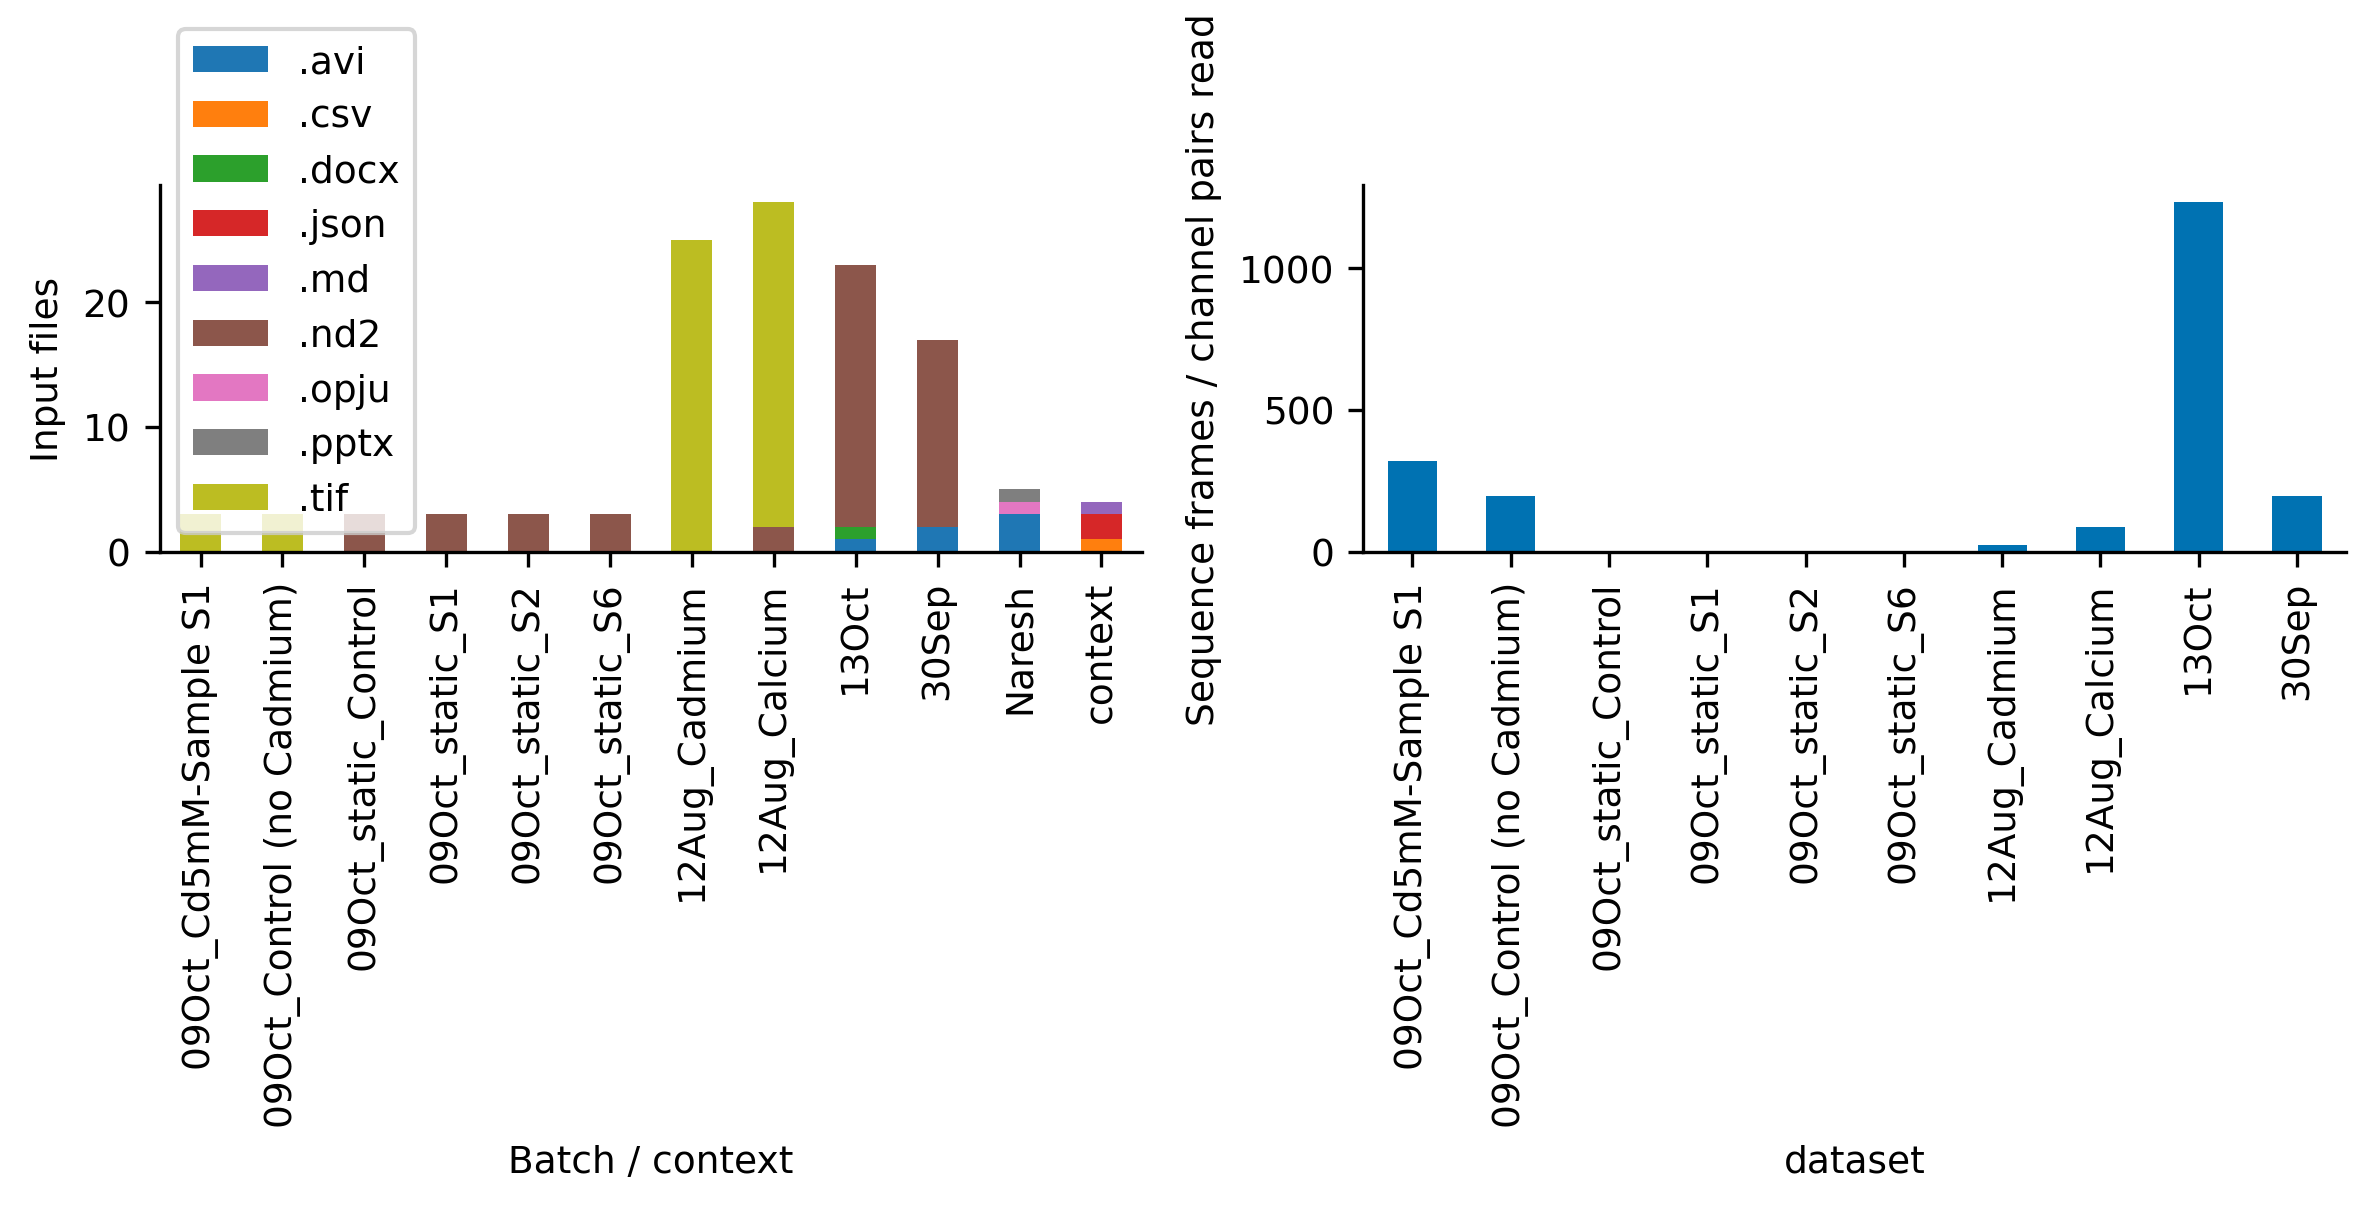

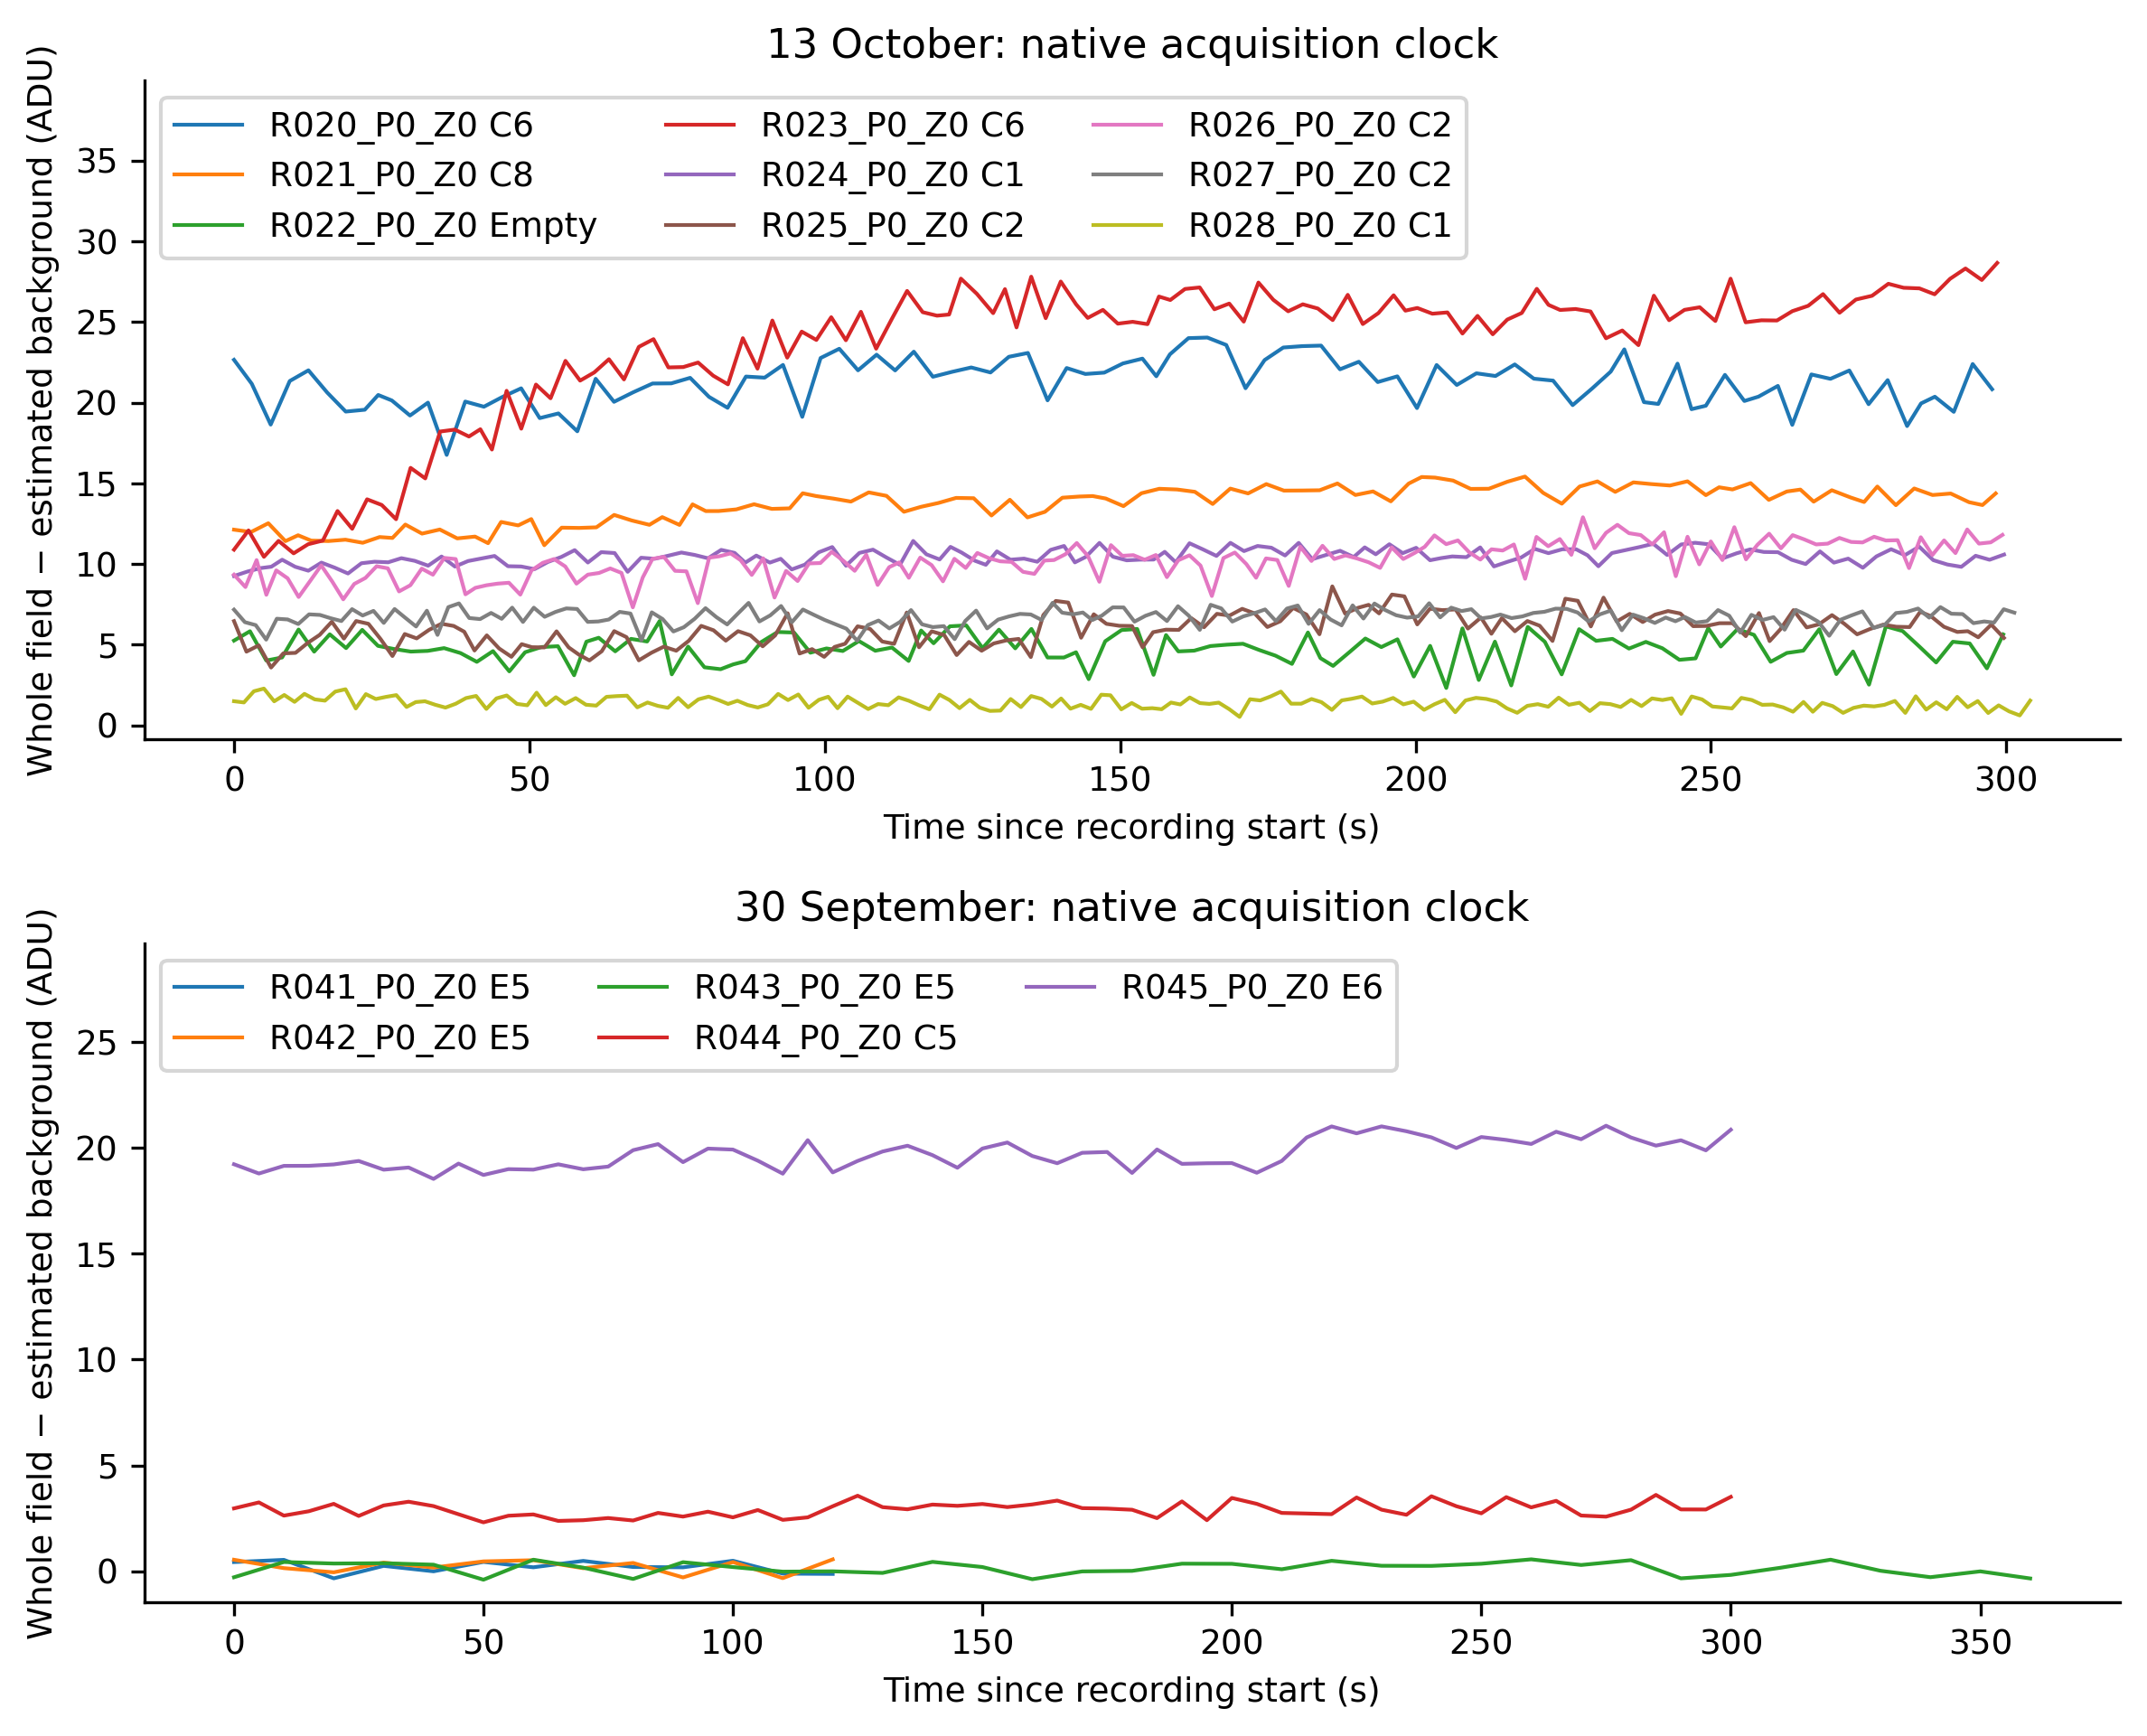

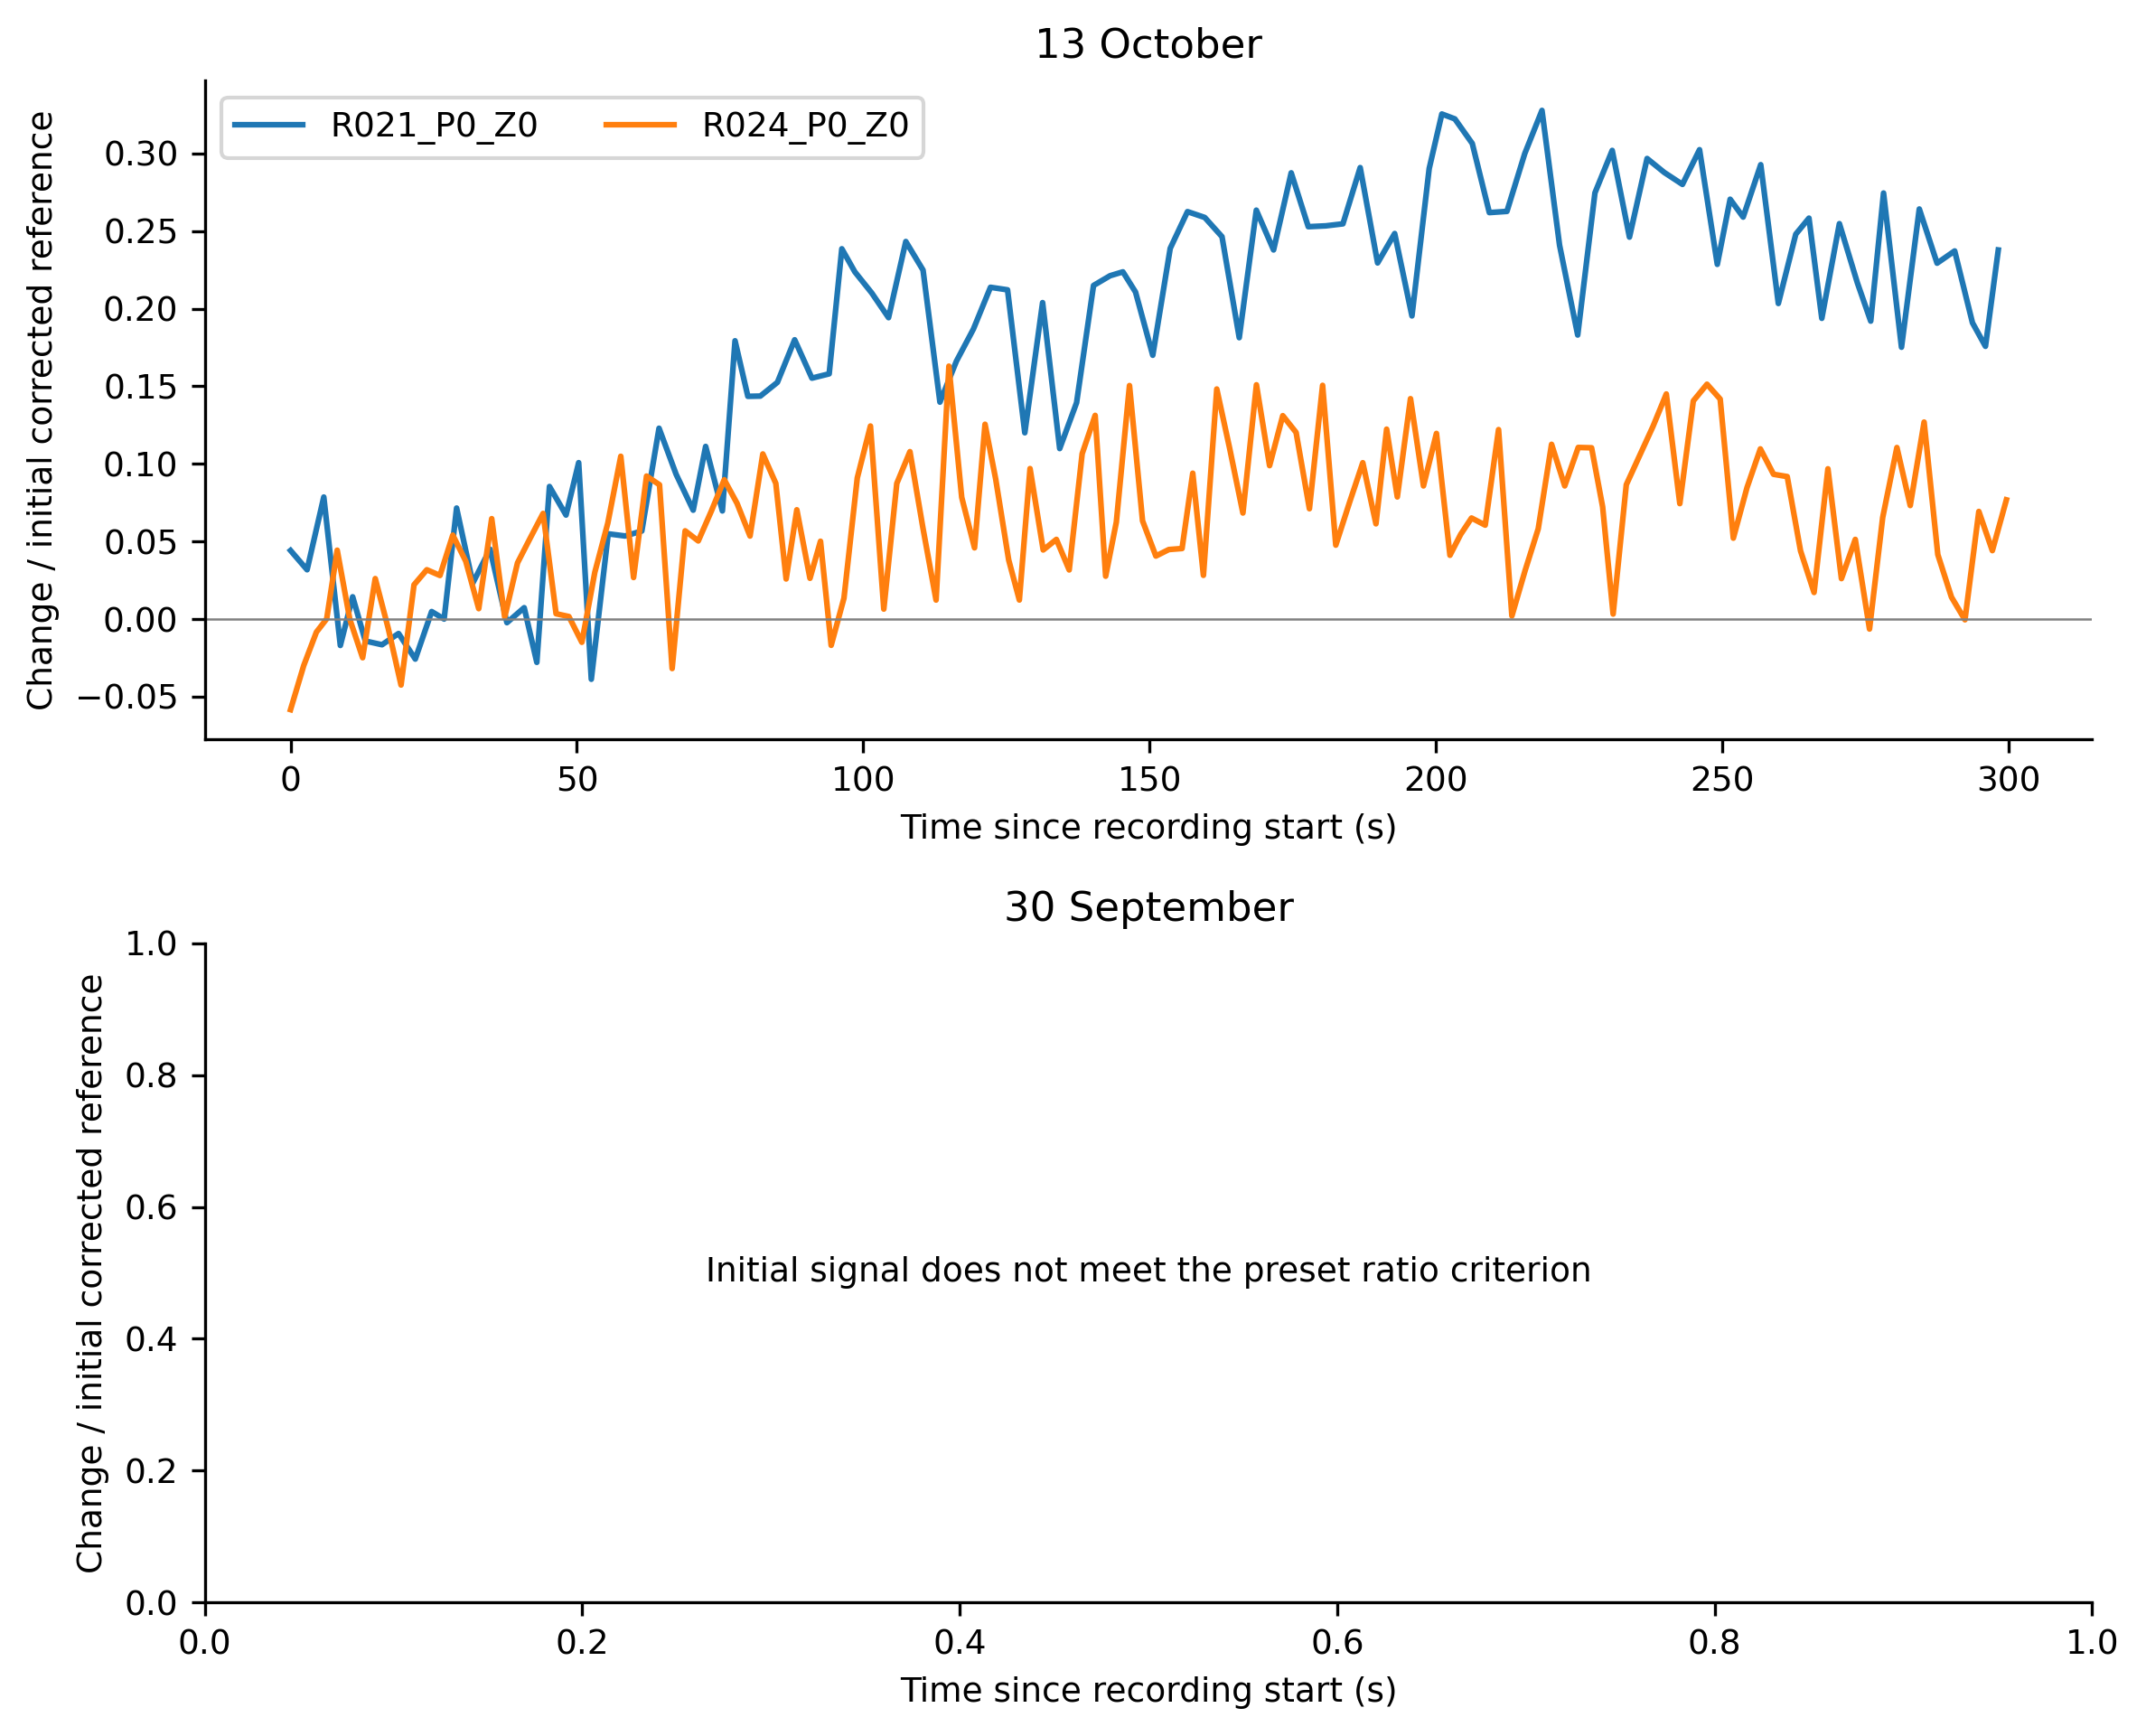

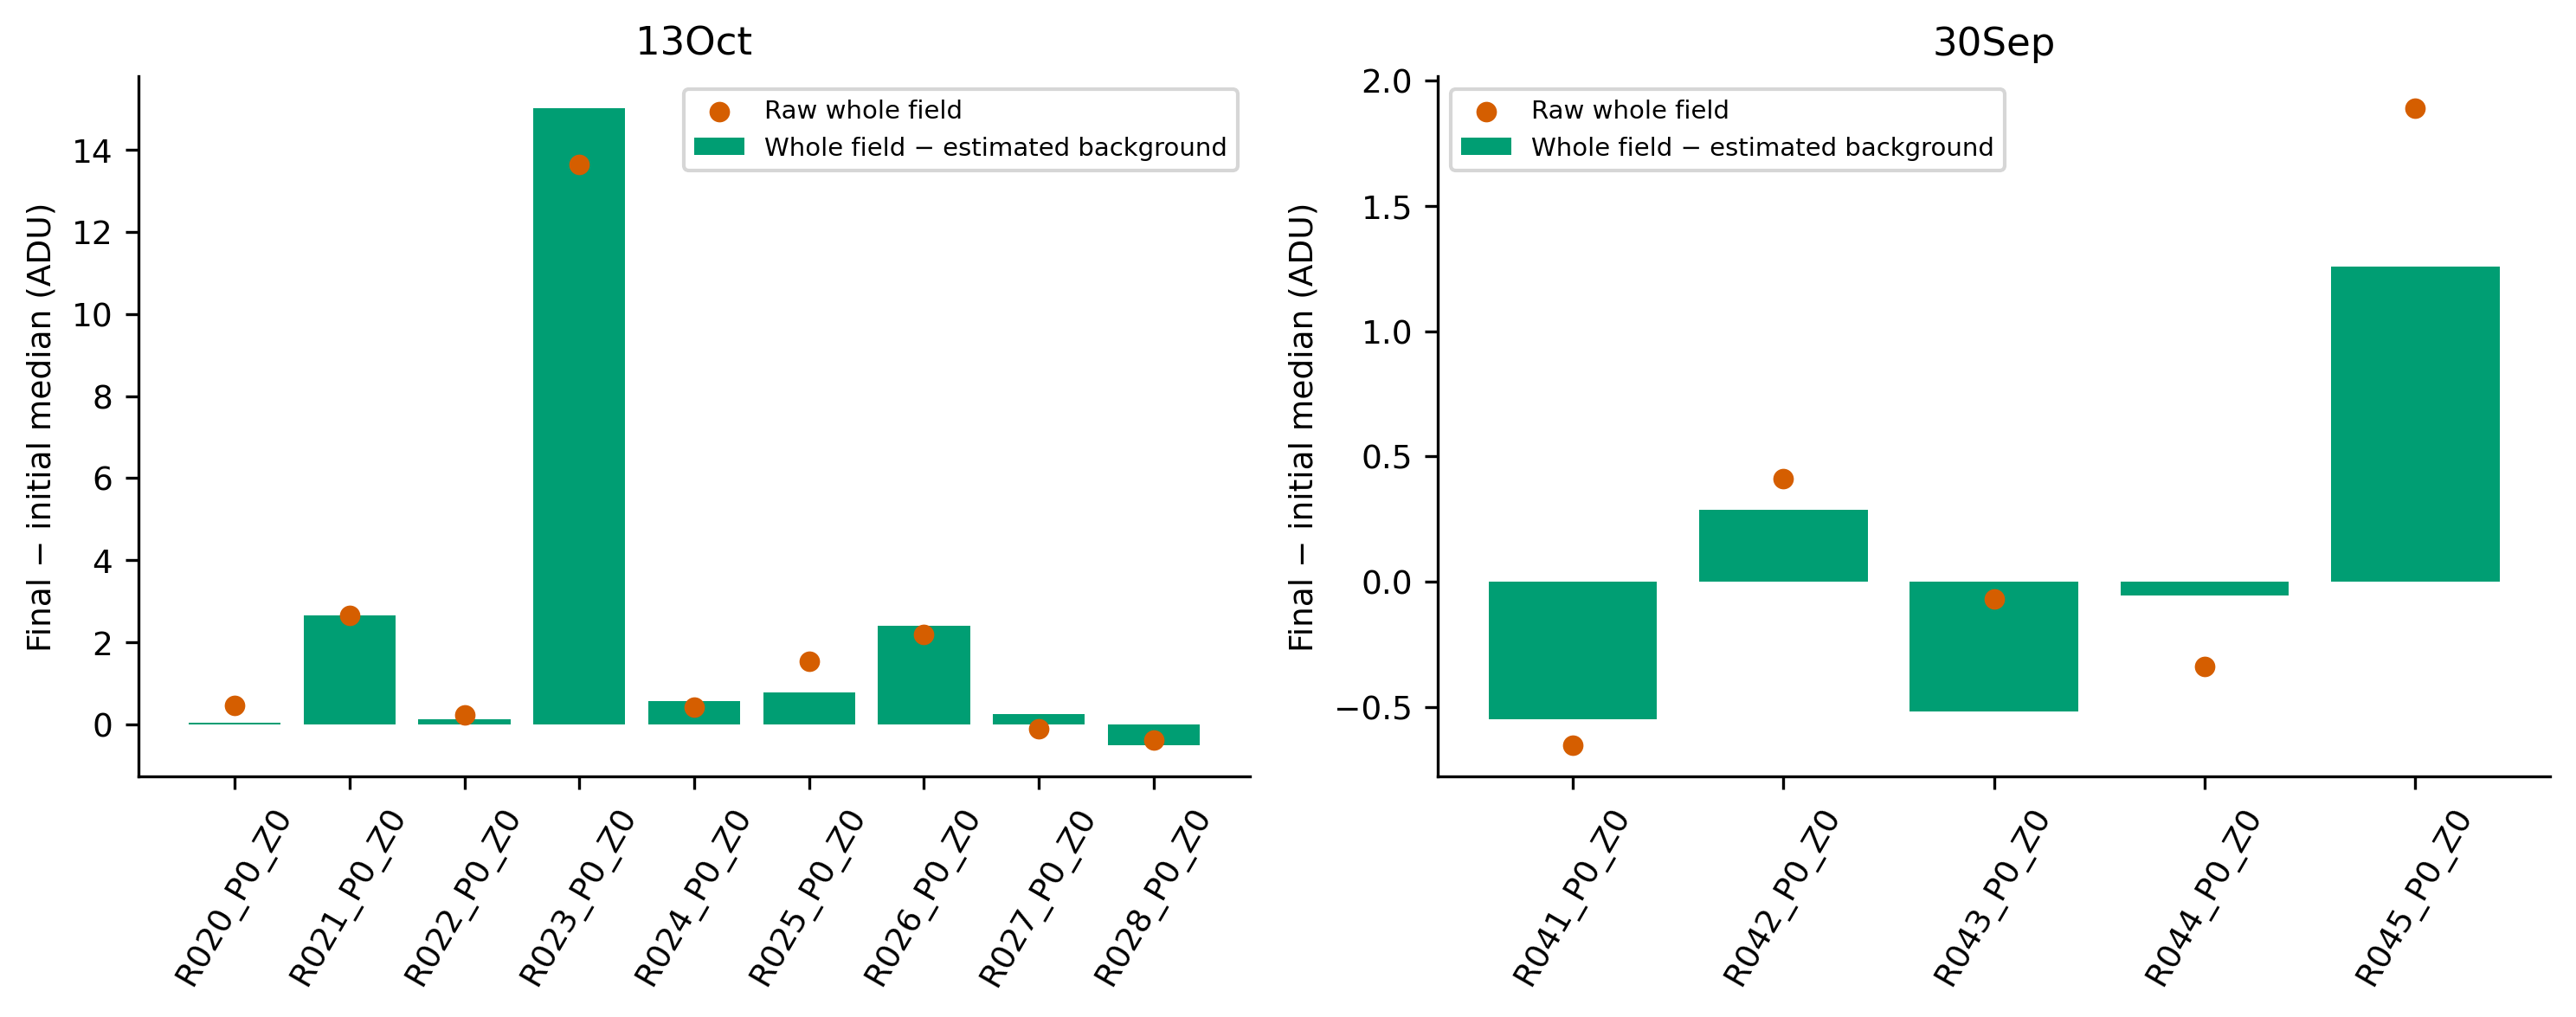

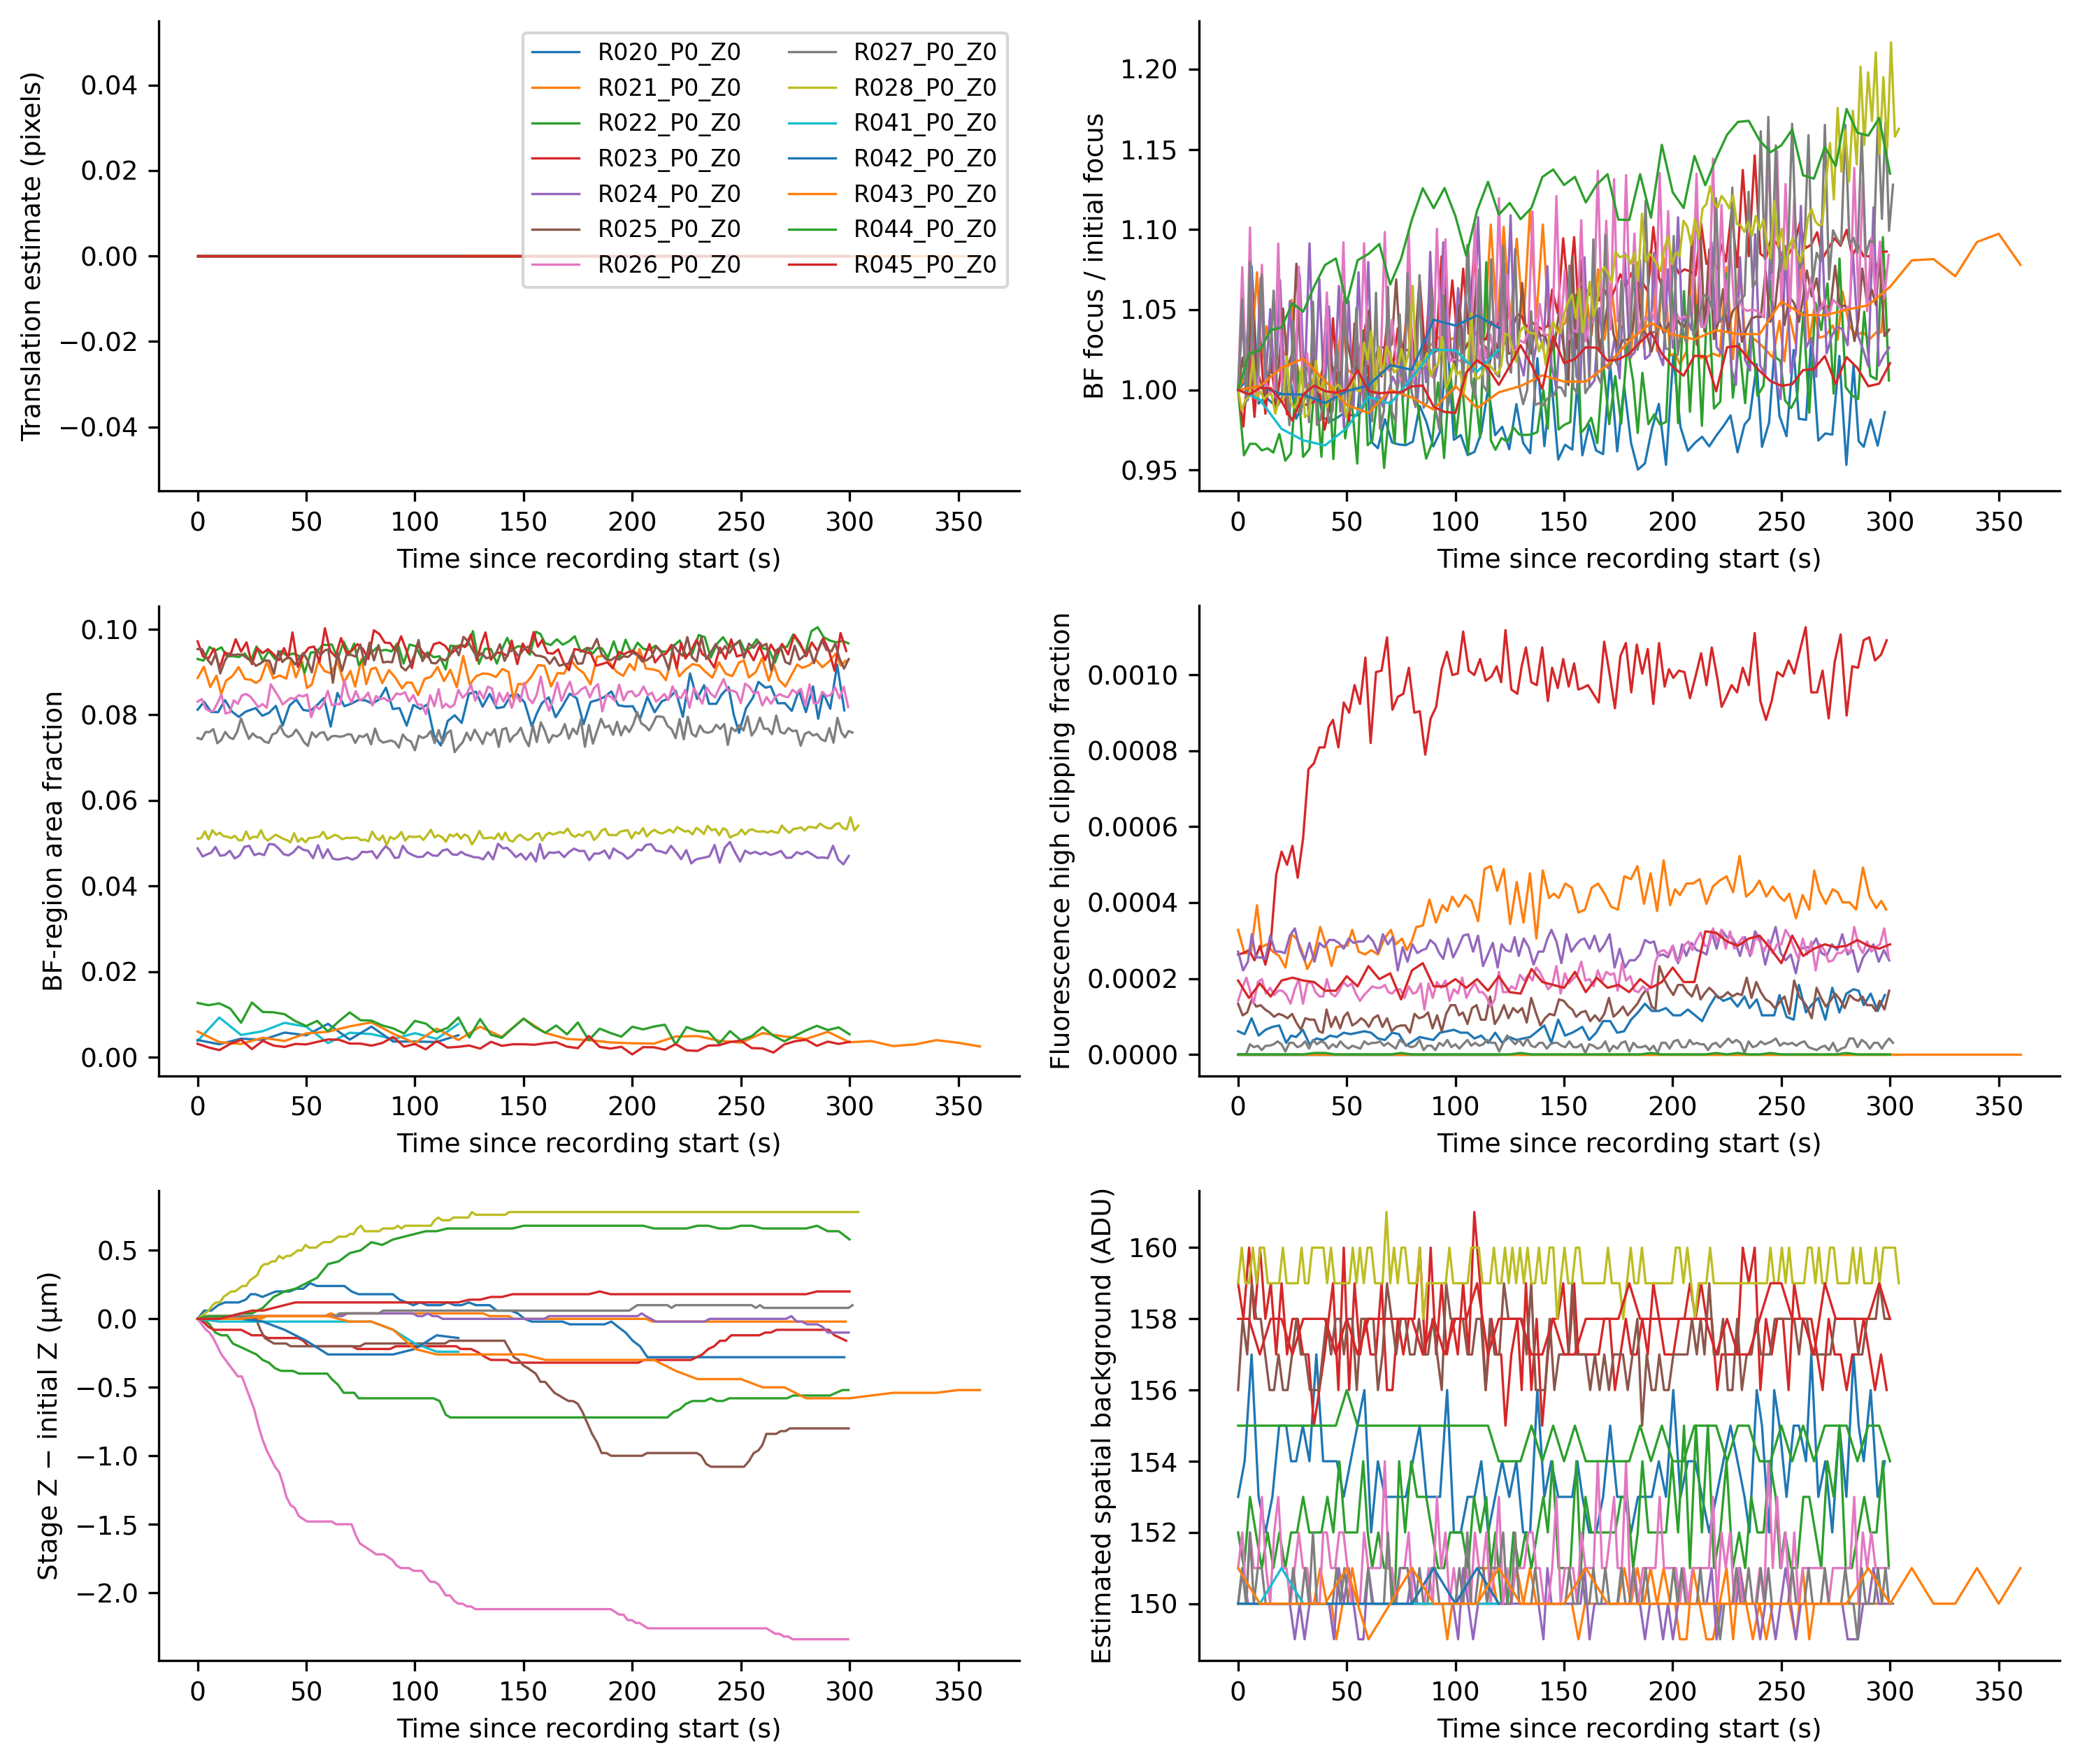

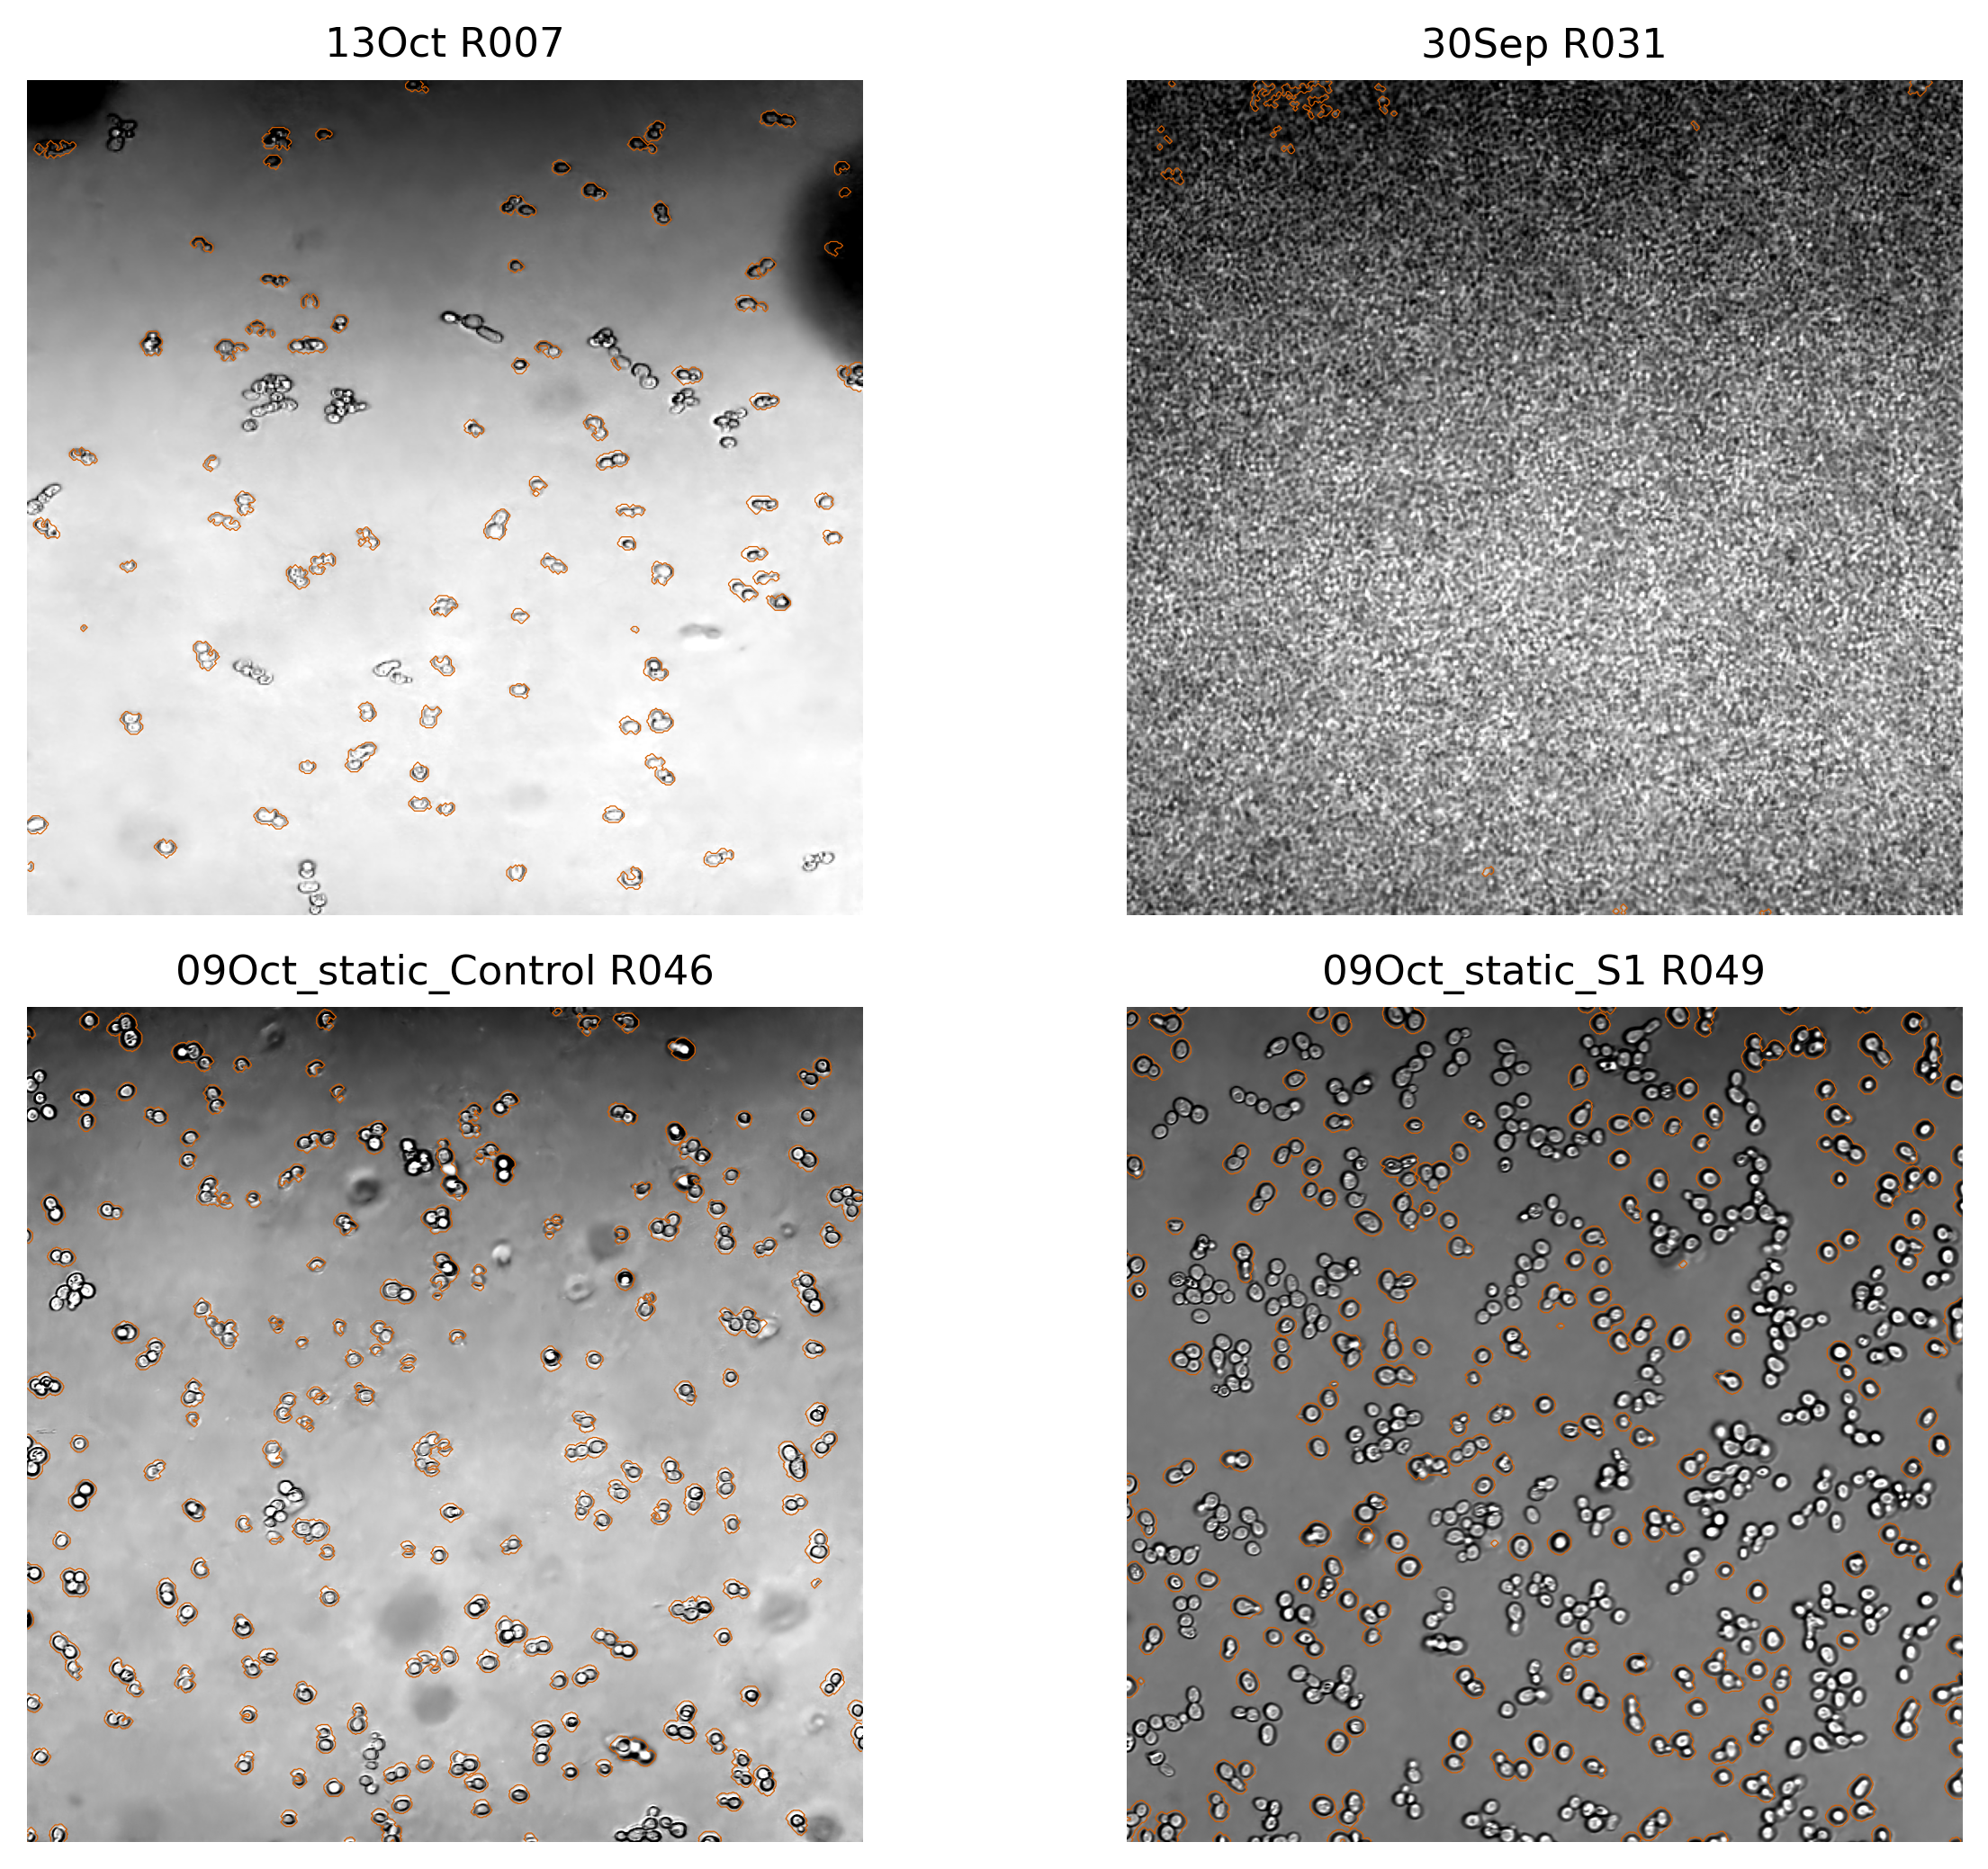

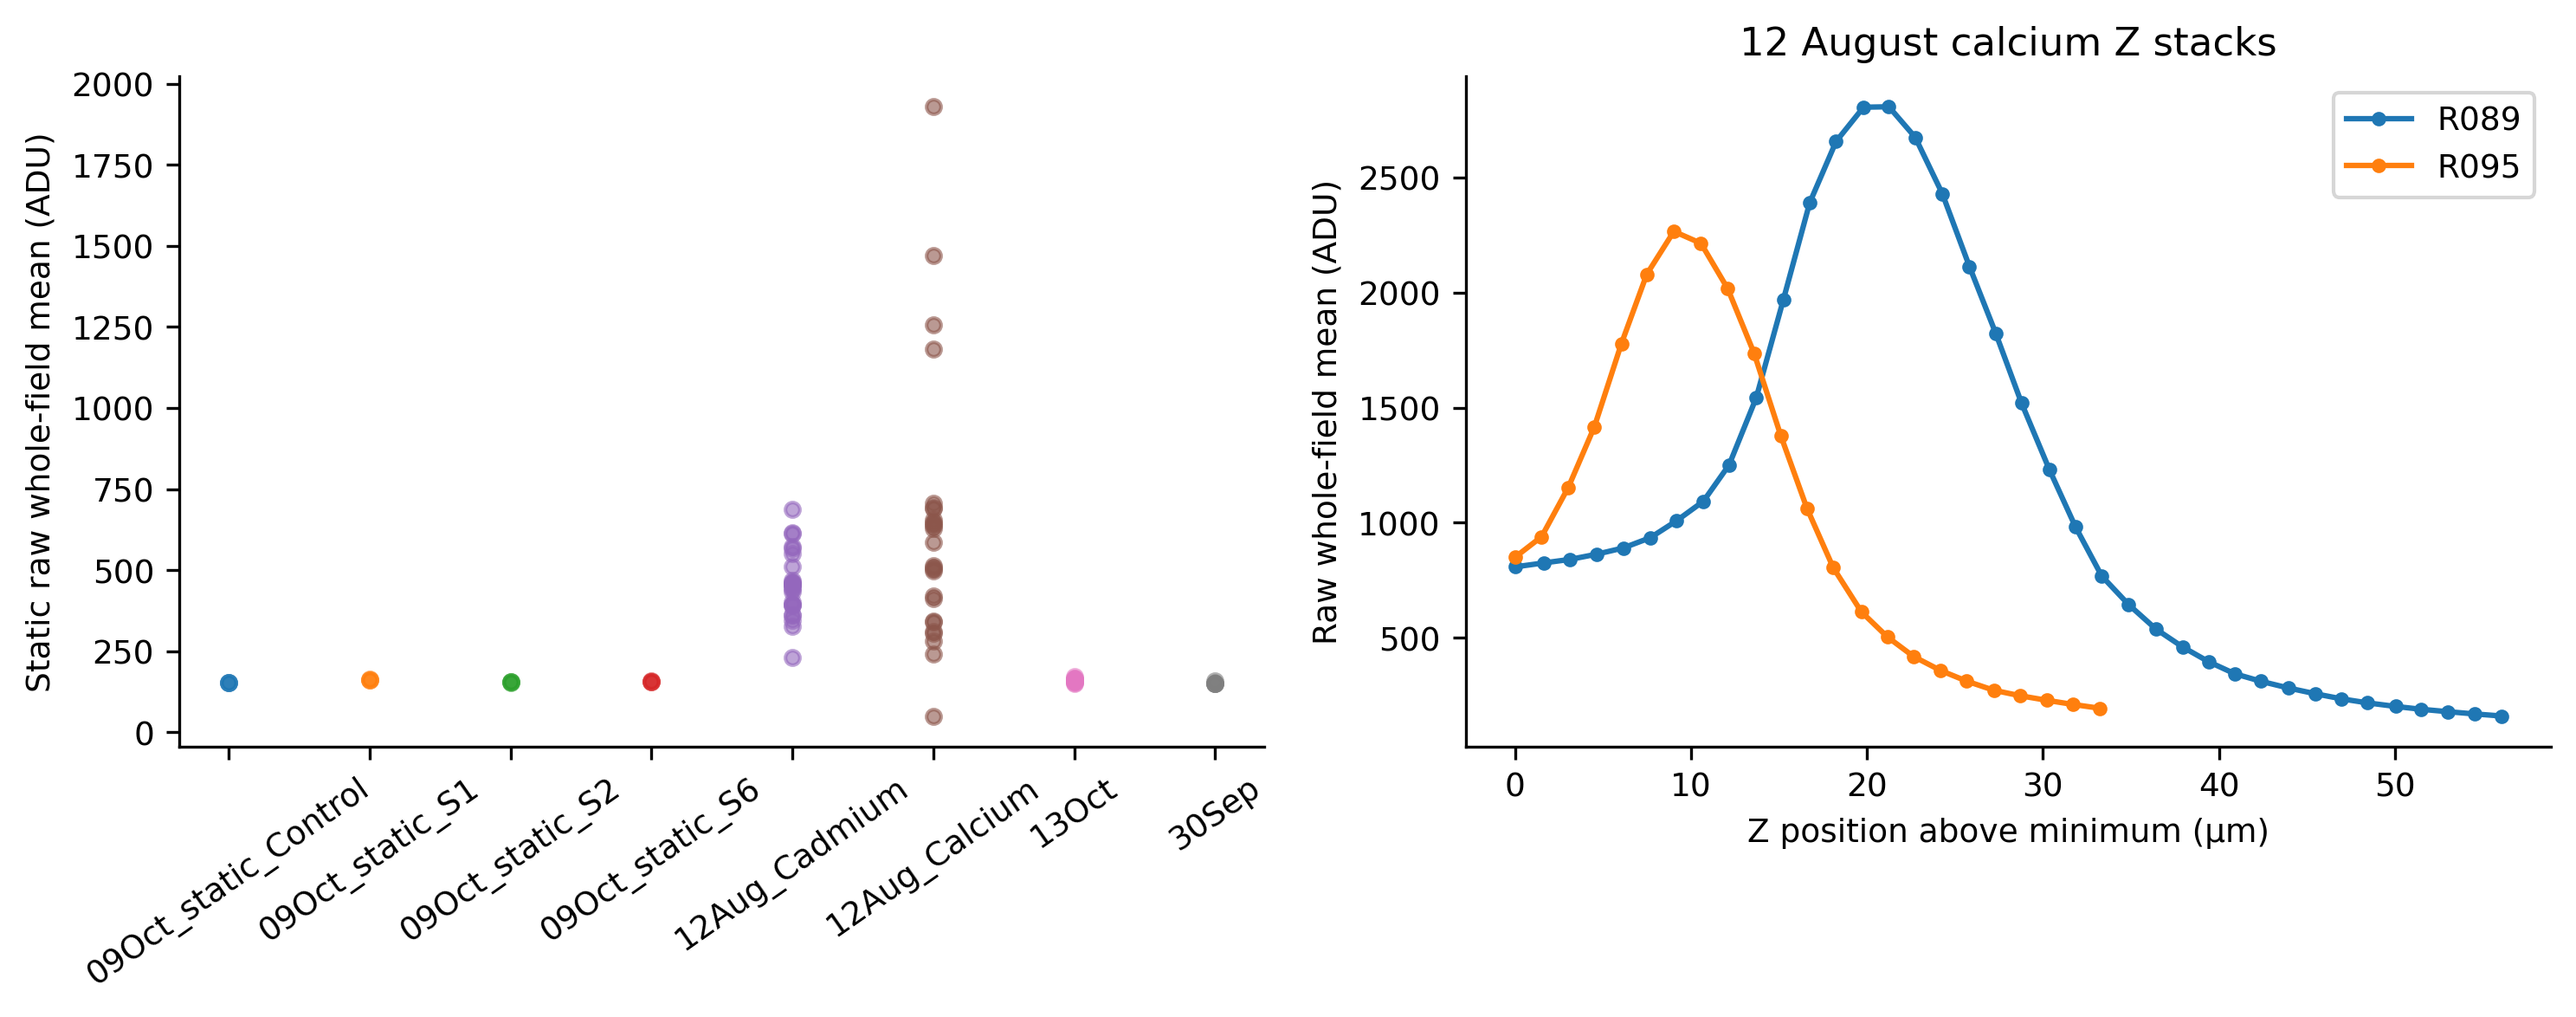

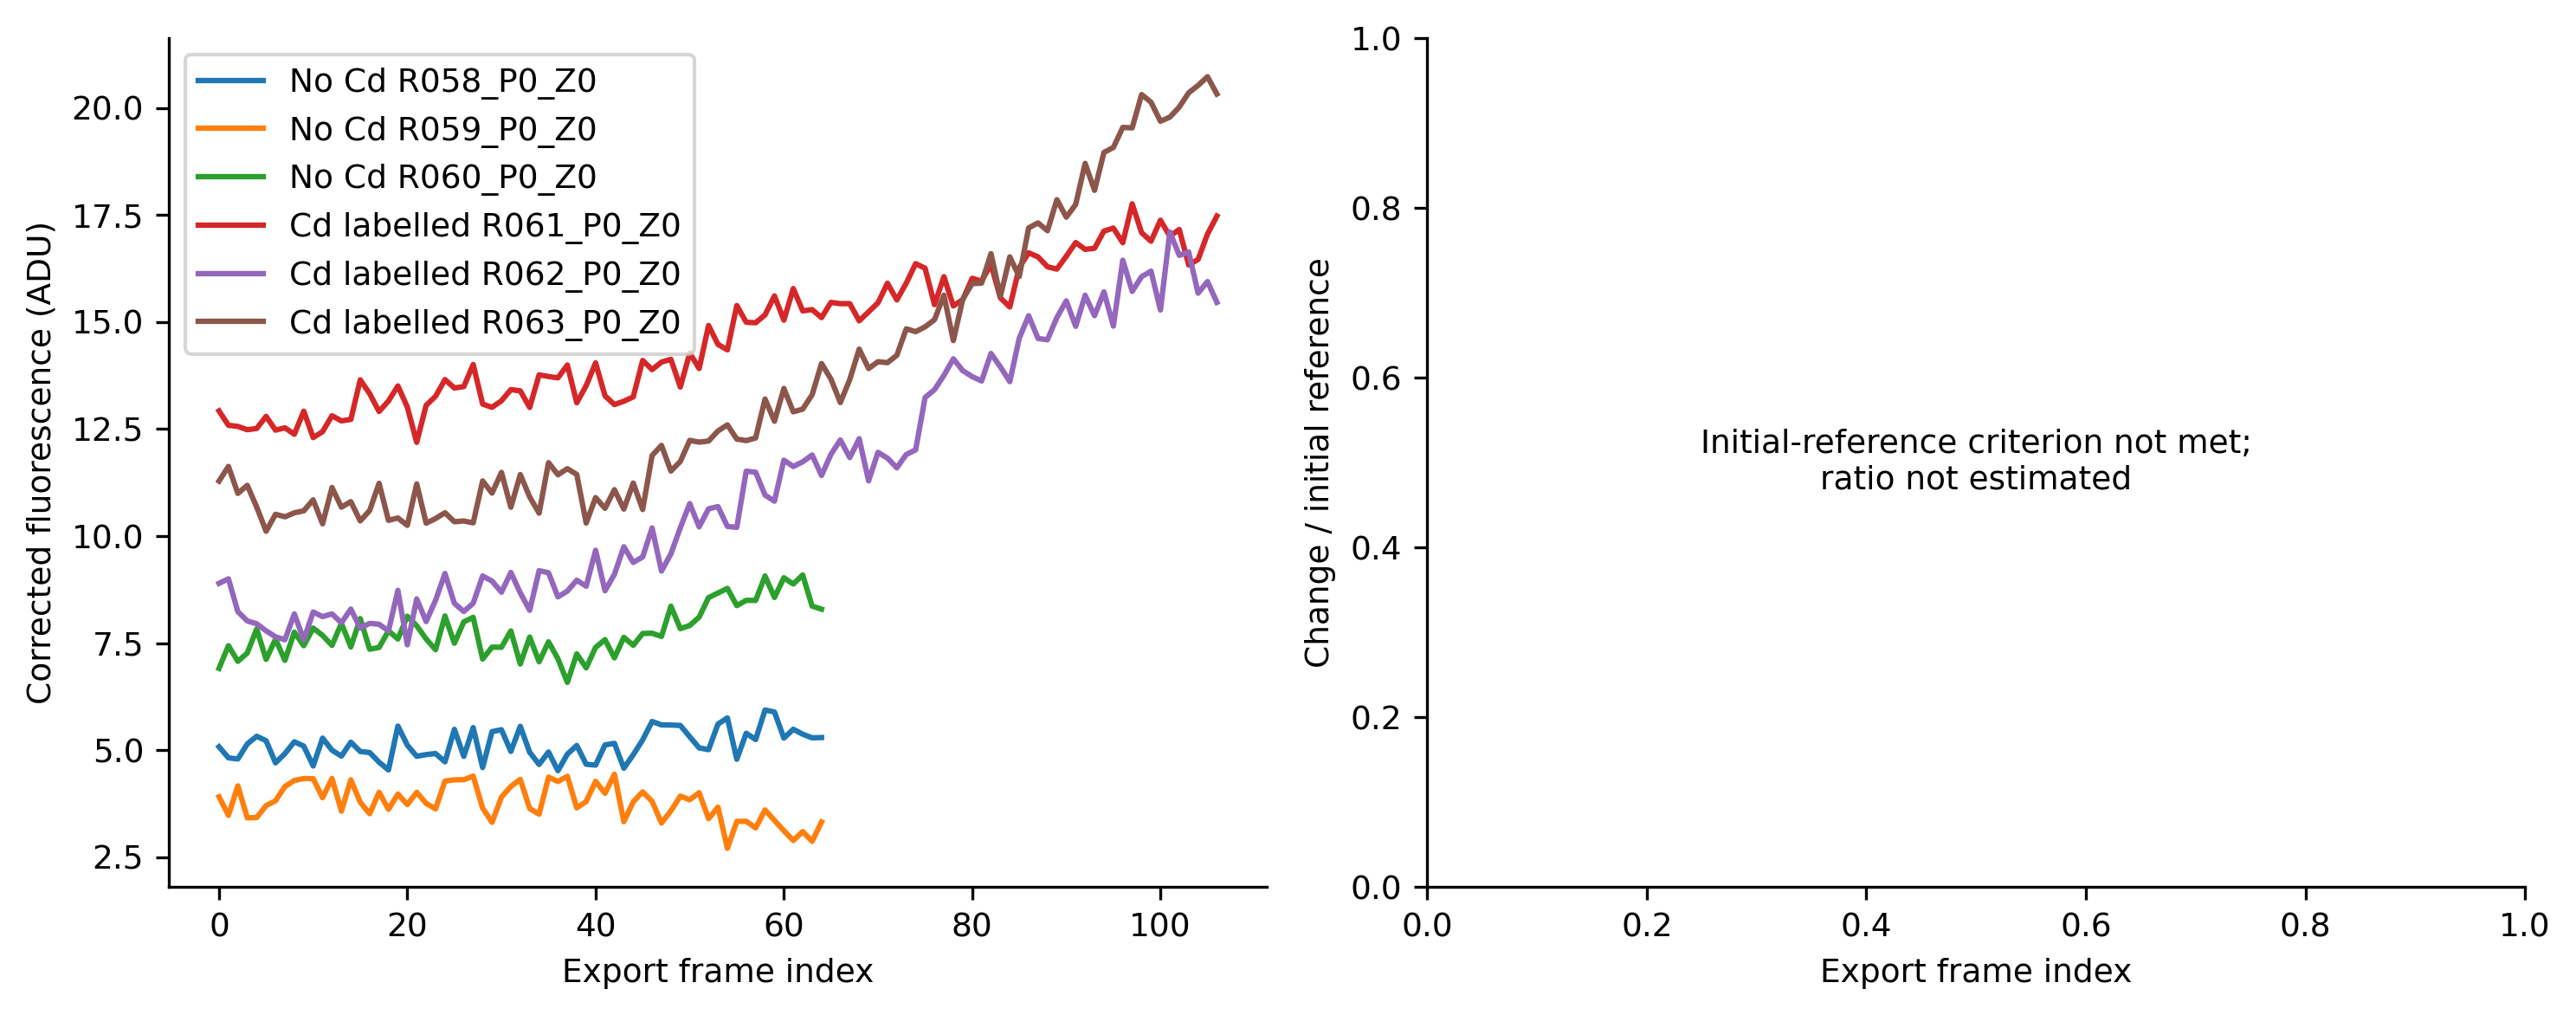

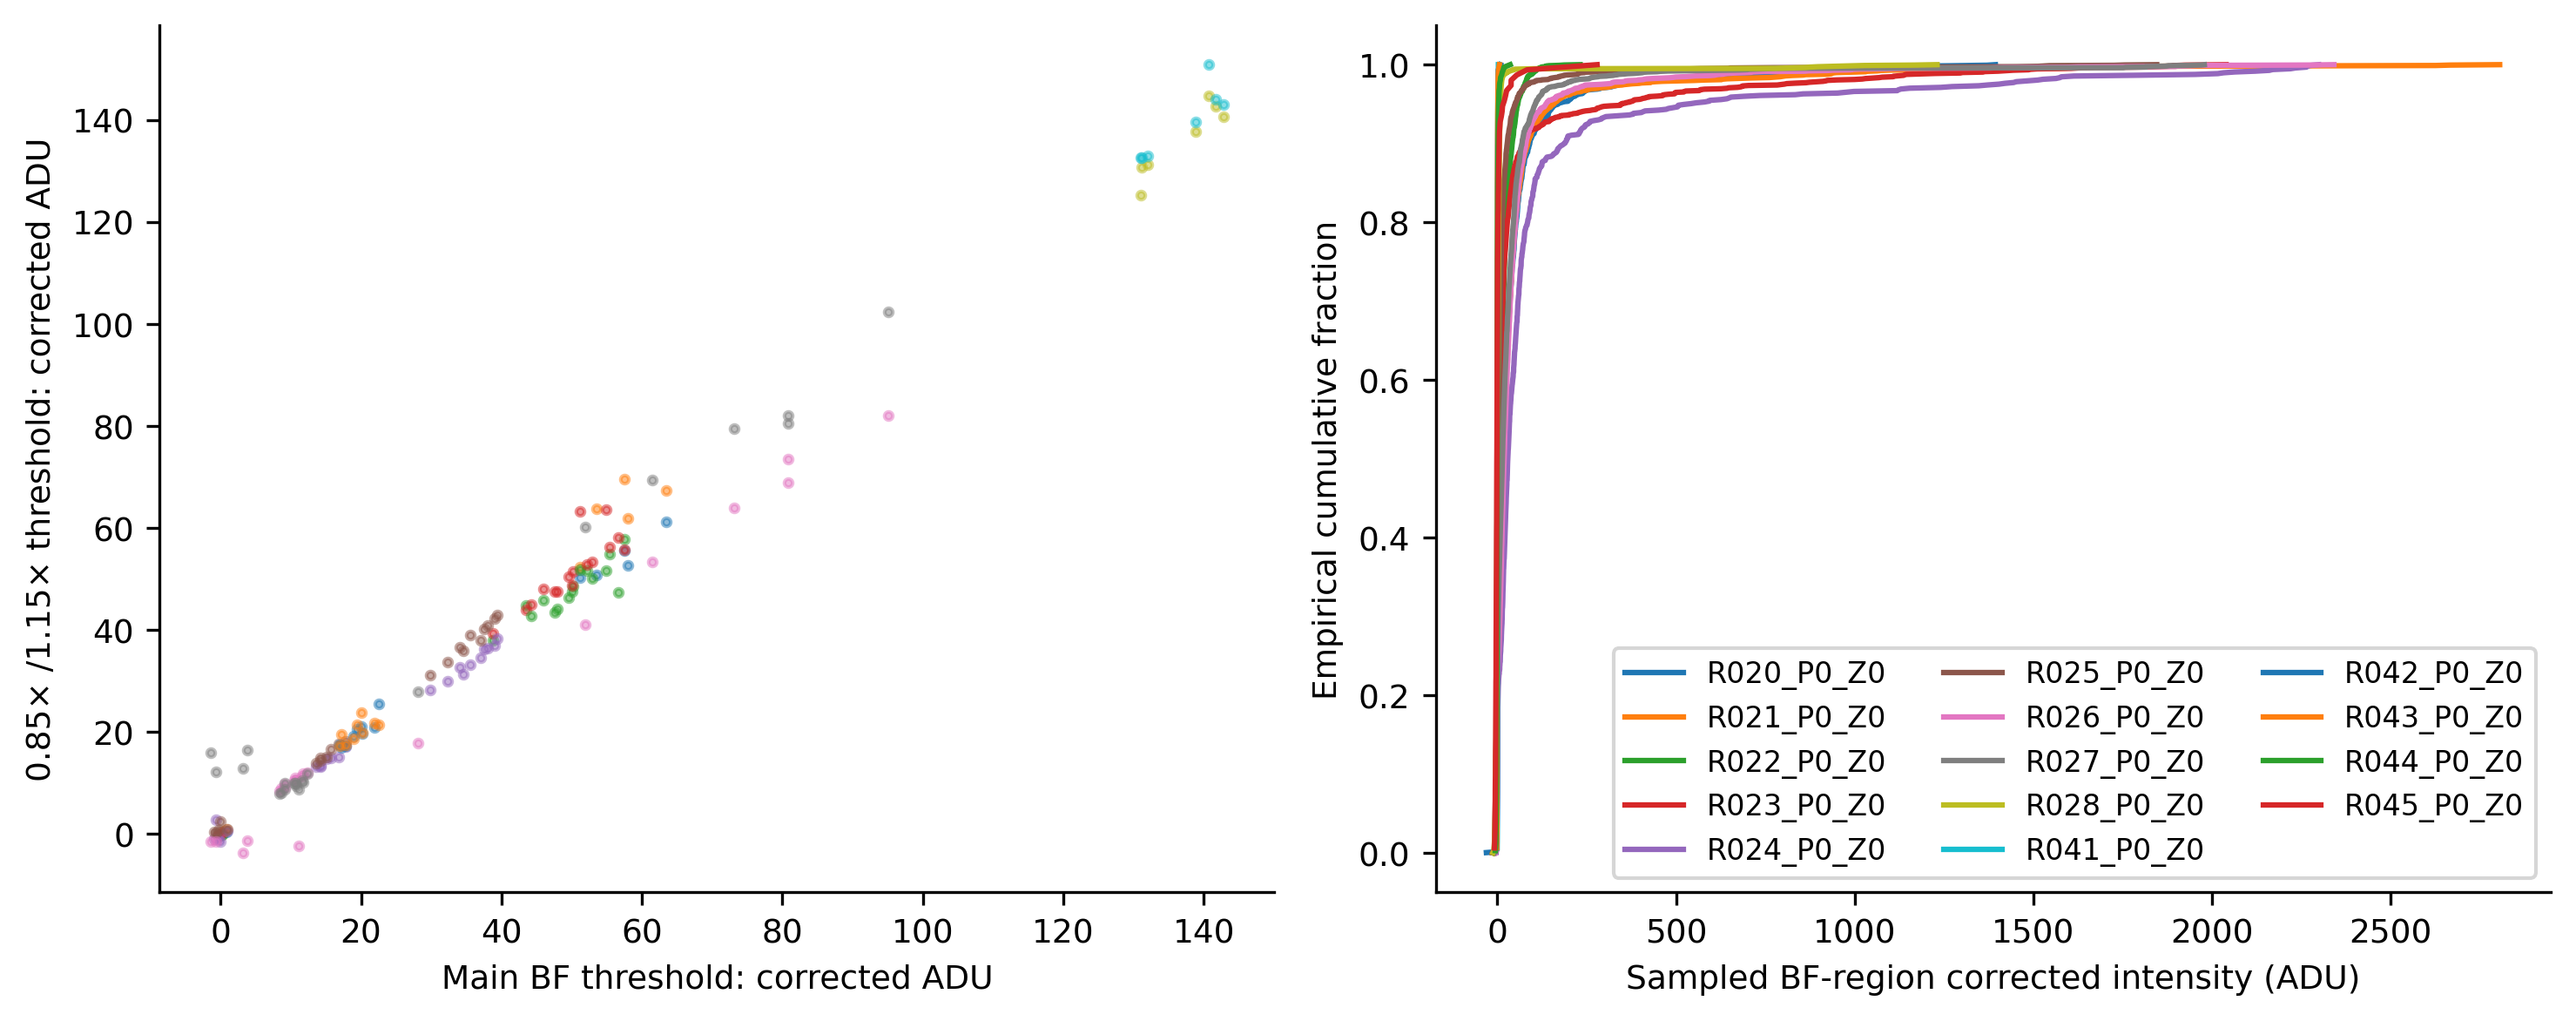

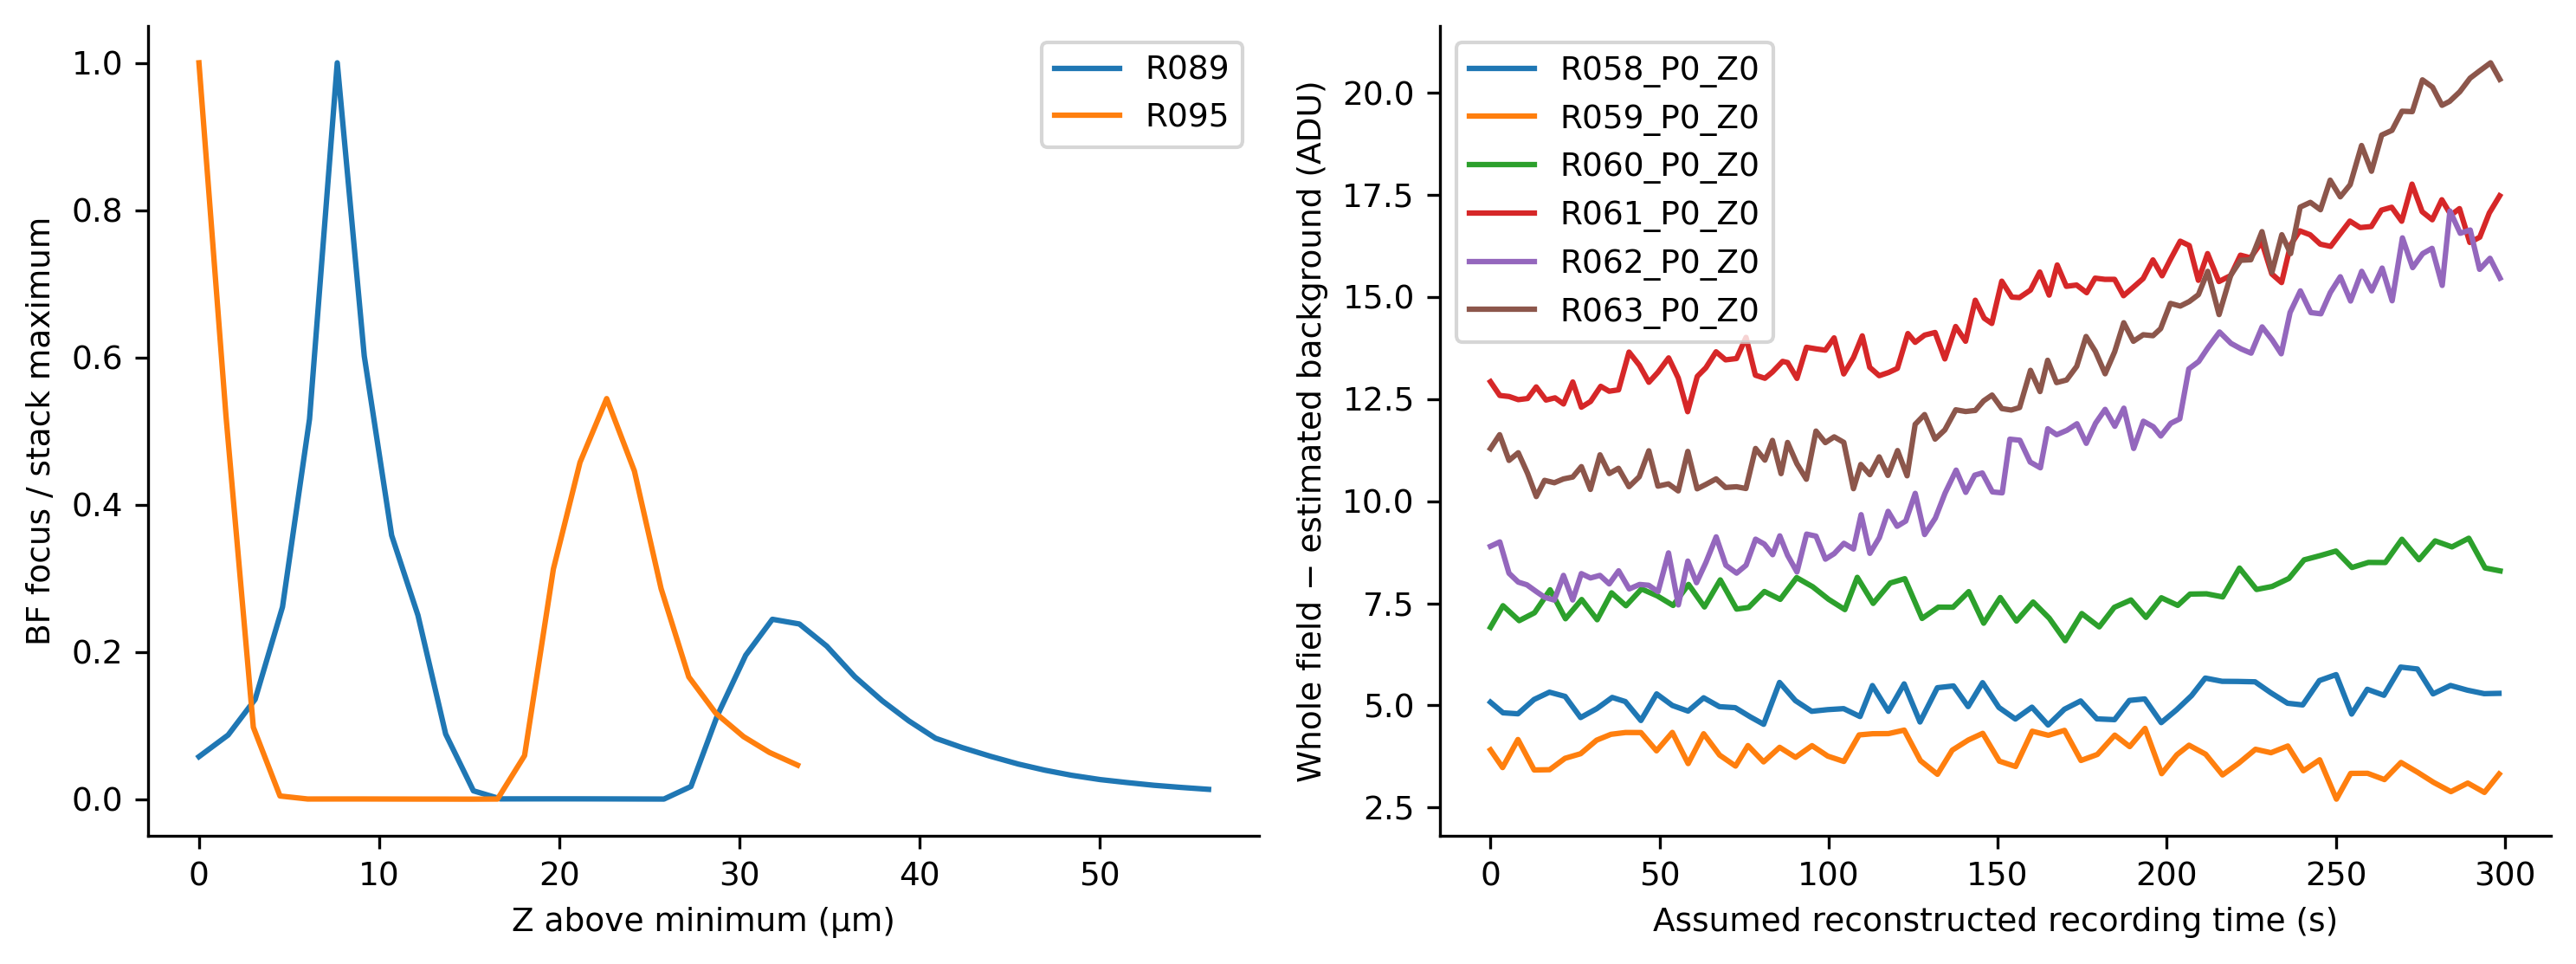

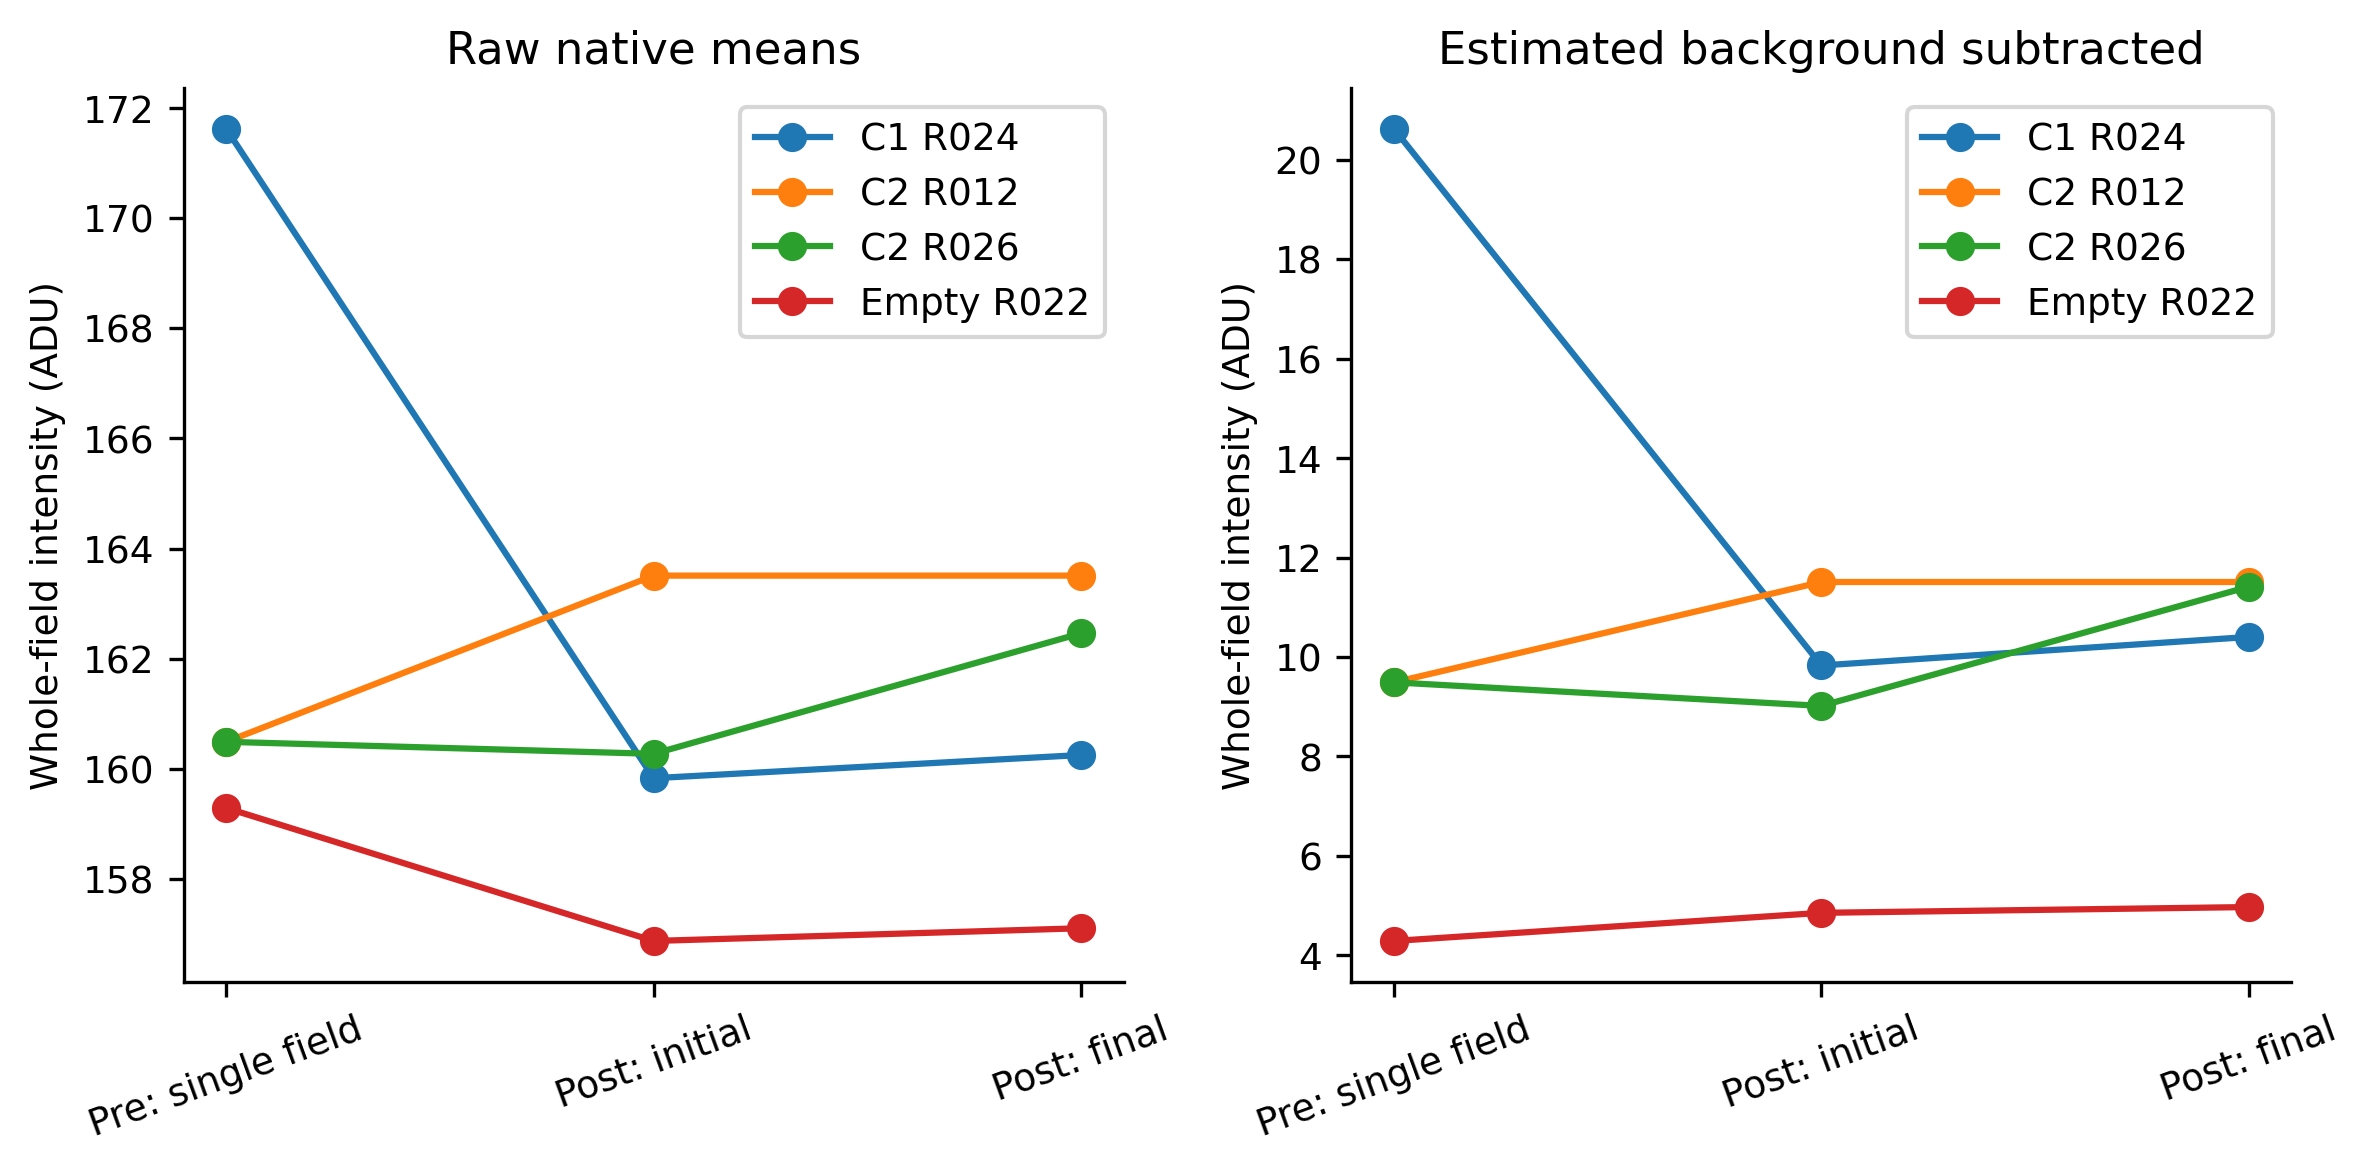

,group,plateau_supported,status
0,R020_P0_Z0,False,no_resolved_plateau
1,R021_P0_Z0,False,no_resolved_plateau
2,R022_P0_Z0,False,no_resolved_plateau
3,R023_P0_Z0,False,no_resolved_plateau
4,R024_P0_Z0,False,no_resolved_plateau
5,R025_P0_Z0,False,no_resolved_plateau
6,R026_P0_Z0,False,no_resolved_plateau
7,R027_P0_Z0,False,no_resolved_plateau
8,R028_P0_Z0,False,no_resolved_plateau
9,R043_P0_Z0,False,no_resolved_plateau


In [8]:
display(Markdown('## Results'))
display(metrics[['group','frames','duration_s','initial_corrected_adu','final_corrected_adu','change_adu','fractional_change','region_review_frames']].round(3))
for item in figures: display(Image(filename=str(OUTPUT/item['file']),width=850))
display(pd.DataFrame(fits))

In [9]:
lookup=manifest.set_index('record')
high=metrics[metrics.file.str.contains('13Oct') & metrics.file.str.contains('10mM-calcium_5mM-cadmium')]
sentence=[]
for row in high.itertuples(index=False):
    sample=lookup.loc[row.record,'original_name'].split('_')[0]
    sentence.append(f'{sample}: {row.change_adu:+.2f} ADU over {row.duration_s:.1f}s')
conclusion='13 October, nominal 10 mM Ca / 5 mM Cd: '+ '; '.join(sentence)+'. '
conclusion+='The C6 recording has the largest within-recording increase in this group. '
pair_selected=[r for r in pair_rows if r['post_frames']>1]
if pair_selected:
    contrast='; '.join(f"{r['sample']} {r['candidate_pre_post_change_adu']:+.2f} ADU" for r in pair_selected)
    conclusion+='Candidate field-matched pre/post contrasts are '+contrast+'. '
conclusion+='Within-recording change and the field-matched treatment contrast answer different questions: the C1 field decreases across its paired acquisitions despite rising slightly within the challenged recording.'
results=[f'{len(manifest)} input files, including derived context, were inventoried and byte-verified; {len(files)} native/export image containers were processed.',
         f'{len(metrics)} time-series acquisitions; {int((metrics.clock=="native ND2 acquisition").sum())} with native clocks. All {len(static)} static/Z frames are retained; {int(static.mean_adu.notna().sum())} contain fluorescence and {int(static.corrected_adu.notna().sum())} have a usable BF-region metric.',conclusion,
         'No recording met the preset resolved-plateau criterion; an empirical reaction time constant, t50 and t90 were not estimated.',
         'Four same-well comparisons meet the stage/BF field-match criterion. Their pre/post contrasts are tabulated separately from within-recording change.',
         'Recorded stage Z spans 2.34 µm in C2 Ca 1 mM / Cd 5 mM and 1.08 µm in C2 Ca 10 mM / Cd 5 mM. PFS Status is code 1 except for three code-5 frames across those two C2 recordings; PFS offsets are constant within all 14 native time series. Codes are retained without assigning a lock-state meaning; stage motion alone does not establish defocus.',
         f'{len(avi)} AVI files were decoded as processed-export QC and were not counted as additional biological observations.']
table_rows=[]
for row in metrics.itertuples(index=False):
    table_rows.append([row.group,lookup.loc[row.record,'file'],f'{row.change_adu:+.2f}',
        f'{row.duration_s:.1f}s' if np.isfinite(row.duration_s) else 'frame-index only','Yes: descriptive recording analysis'])
summary=dict(title='F-01 | Native microscopy fluorescence analysis',
    question='How does recorded fluorescence change across the supplied cadmium-labelled microscopy acquisitions?',
    materials=['116 original supplied files and 4 derived context files; ND2, TIFF, AVI and experimental notes; original intensities preserved.',
               f'nd2 {nd2.__version__}; tifffile {tifffile.__version__}; scikit-image {skimage.__version__}; SciPy {scipy.__version__}.'],
    methods=['Stream native frames; distinguish T,C,P,Z axes; cross-check ND2 timestamps against per-frame metadata. Use acquired event Z coordinates and cross-check optical stacks against Z index and planned positions.',
             'Whole-field native means are primary. Estimate spatial background outside BF-derived regions; keep raw means and a 10th-percentile background sensitivity.',
             'BF high-pass regions use a fixed initial threshold, 1 µm expansion and 4–150 µm² area limits. Regions are not validated cells.',
             'Initial/final 10% medians; fractional changes only above 5× spatial noise. Fixed-mask and 0.85/1.15 threshold sensitivity; every-frame clipping, focus and drift.',
             'Retain all frames. AVI is secondary export QC; old Z stacks and static fields are not time courses.'],
    scope_and_assumptions=['Conditions are nominal: 1 mM Cd stock contradicts the 5 mM labels. The C2 Ca 0/1 mM filename conflict is retained.',
        'Initial reference is recording-relative, not a verified pre-Cd baseline. TIFF clocks conflict; frame-index analysis only.',
        'Denoise.ai ON means acquisition-processed data, not unprocessed detector counts. BF-region masks do not establish single-cell identities; dense 30 September masks are incomplete.',
        'Native time-series exposure event values are missing and are not imputed from static-image 10 ms metadata. Stage Z varies, but focus compensation can move the objective; PFS state codes are opaque here. Pairs remain conditional on optical comparability. C1/Empty pairs change both Ca and Cd, so they do not isolate Cd.',
        'Fields/cells/frames/exports are not independent cultures. No automatic photobleach correction, culture p-values, binding or calibrated dose model.'],
    results=results,conclusion=conclusion,figures=figures,
    references=['Chen et al. (2013), Ultrasensitive fluorescent proteins for imaging neuronal activity. https://doi.org/10.1038/nature12354',
                'Montero Llopis et al. (2021), Best practices and tools for reporting reproducible fluorescence microscopy methods. https://doi.org/10.1038/s41592-021-01156-w',
                'nd2 official documentation: https://talleylambert.com/nd2/',
                'scikit-image registration documentation: https://scikit-image.org/docs/stable/api/skimage.registration.html',
                'Nikon Perfect Focus System: near-infrared focus compensation maintains objective-to-coverslip position. https://www.microscope.healthcare.nikon.com/en_EU/resources/glossary/perfect-focus-system',
                'Supplied 13 October lab notebook, body.b0029 (condition table), b0037–b0069 (prior qualitative observations).',
                'Biomni methods review supplied in F01_biomni_methods_review.json; no arbitrary drift cutoff adopted.'],
    table=dict(columns=['Record','Input data','Final − initial (ADU)','Time coverage','Finished without more wet-lab data'],rows=table_rows),
    core_metrics=metrics.to_dict(orient='records'))
save_json('summary.json',summary)
hashes_after={f:sha(INPUT/f) for f in manifest.file}
assert all(hashes_after[r.file]==r.sha256 for r in manifest.itertuples()),'Input mutated'
save_json('scientific_qa.json',dict(input_hashes_pass=True,input_hashes_after_pass=True, failures=failure_rows,all_frame_rows=len(frames),
    native_clock_crosscheck_pass=True,time_series=len(metrics),fits=fits,
    source_count=len(manifest),image_containers=len(files),every_frame_retained=True,
    static_Z_frames=len(static),static_Z_fluorescence_frames=int(static.mean_adu.notna().sum()),
    static_Z_BF_region_metric_available=int(static.corrected_adu.notna().sum()),
    Z_coordinates='Native event Z Coord preferred; planned Z-Series/index cross-checked for optical stacks',
    masks_fluorescence_independent=True,condition_identity='documented labels; no sequencing confirmation'))
save_json('provenance.json',dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
    nd2=nd2.__version__,scipy=scipy.__version__,skimage=skimage.__version__,tifffile=tifffile.__version__,
    inputs=dict(zip(manifest.file,manifest.verified_sha256)),analysis='native pixels; BF-defined region summaries'))
display(Markdown('## Interpretation\n'+conclusion))

## Interpretation
13 October, nominal 10 mM Ca / 5 mM Cd: C8: +2.66 ADU over 298.2s; Empty: +0.12 ADU over 299.5s; C6: +15.01 ADU over 298.4s; C1: +0.57 ADU over 299.6s; C2: +0.77 ADU over 299.6s. The C6 recording has the largest within-recording increase in this group. Candidate field-matched pre/post contrasts are C1 -10.22 ADU; C2 +1.92 ADU; Empty +0.68 ADU. Within-recording change and the field-matched treatment contrast answer different questions: the C1 field decreases across its paired acquisitions despite rising slightly within the challenged recording.